# 01 · Extracción: del archivo escaneado y la entrevista al texto buscable

**Tarea 2 – Voces y documentos peruanos.** OCR de 25 documentos peruanos (impresos, fotos y manuscritos) y transcripción automática (ASR) de entrevistas en español peruano, con seudonimización, limpieza y EDA.

## 1. Configuración inicial

**Fecha de extracción de los archivos crudos:** 23 de octubre de 2026 (`doc_028`, reemplazo de `doc_024`, el 24 de octubre de 2026; `doc_029`, reemplazo de `doc_013`, el 25 de octubre de 2026).

### Entorno y versiones

Se usa el entorno del curso (`Data-Science-Python`, Python 3.12) con los grupos de las sesiones 10 y 13:

```bash
uv sync --group docai --group audio   # los dos juntos: uv sync desinstala los grupos que no se nombran
```

| Componente | Versión | Modelo y configuración prevista |
|---|---|---|
| OCR | PaddleOCR 3.7.0 (PaddlePaddle 3.3.1, PaddleX 3.7.2) | `PaddleOCR(lang="es")`, CPU |
| ASR | faster-whisper 1.2.1 (CTranslate2 4.8.2) | Whisper large-v3-turbo (`mobiuslabsgmbh/faster-whisper-large-v3-turbo`), int8 en CPU, VAD Silero activado, `language="es"` |
| Diarización | pyannote.audio 4.0.7 | WeSpeaker ResNet34 (`pyannote/wespeaker-voxceleb-resnet34-LM`) + clustering jerárquico |
| Seudonimización y métricas | rapidfuzz 3.14.6, jiwer 4.0.0 | `seudonimizar()` de `voz.py`; CER/WER en `02_evaluacion.ipynb` |

La celda de código siguiente comprueba estas versiones en el kernel que ejecuta el notebook. Los nombres exactos de los modelos de detección y reconocimiento de PaddleOCR se registran al cargarlo en la sección de OCR.

### Fuentes y licencias

Todos los archivos vienen de **Wikimedia Commons** y tienen licencia libre o están en dominio público. El detalle por archivo (autor, licencia y enlace) está en `datos/fuentes.csv` y `datos/atribucion.csv`.

| Corpus | Contenido | Autores / fuentes | Licencias |
|---|---|---|---|
| Documentos: 8 impresos (`doc_001`–`doc_008`) | Decretos, lineamientos y comunicados oficiales de 2020 (página 1 de cada PDF) y una página de *El Peruano* de 1844 | Presidencia de la República, PCM, Minsa, *El Peruano* | Dominio público (8) |
| Documentos: 8 fotos (`doc_009`–`doc_011`, `doc_014`–`doc_016`, `doc_027`, `doc_029`) | Documentos fotografiados en exposiciones y vitrinas (láminas de Guamán Poma, Casa Museo Ricardo Palma, *Estado General* del monitor *Huáscar* enmarcado tras un vidrio), carteles COVID-19 y un panel informativo de la Huaca Melgarejo. `doc_012` (*El Peruano* n.° 1 en una vitrina) se descartó por casi ilegible tras el OCR y lo reemplaza `doc_027`; `doc_013` (*Nueva corónica* abierta en una vitrina) se descartó por ilegible durante la auditoría del LLM y lo reemplaza `doc_029` | Instituto Cervantes de Tokio, Municipalidad de Miraflores, Milena Casco 2002, Cifras Confiables, Rocio Nury Jara Jala, Ministerio de Defensa del Perú; `doc_012`: Id hiroki; `doc_013`: Palnatoke | CC BY-SA 2.0 (3), CC BY-SA 4.0 (3), CC BY 2.0 (2); descartados: `doc_012` CC BY-SA 4.0, `doc_013` CC BY-SA 3.0 |
| Documentos: 9 manuscritos (`doc_017`–`doc_022`, `doc_025`, `doc_026`, `doc_028`) | *Relación de la Provincia de Saña* (s. XVIII, 6 imágenes), *Relación de antigüedades deste reyno del Pirú* (1613), una partida de bautismo del s. XVIII y el *Acta de la Independencia del Perú* (1821, edición facsimilar). `doc_023` (*Idea general del Reino del Perú*, s. XVIII) se descartó por ilegible tras el OCR y lo reemplaza `doc_026`; `doc_024` (partida de bautismo de 1897) se descartó por tener las letras desvanecidas y lo reemplaza `doc_028` | Bibliothèque nationale de France (Gallica), Santa Cruz Pachacuti, Gabriela lavarello de velaochaga, Murillo Perú; `doc_023`: Universidad de Granada; `doc_024`: Parroquia de San Clemente de Pisco | Dominio público (7), CC BY-SA 4.0 (1), CC BY-SA 3.0 (1); descartados: `doc_023` CC BY-SA 3.0, `doc_024` dominio público |
| Audio: 22 clips (`clip_001`–`clip_022`) | Entrevistas callejeras y testimonios en español peruano (Lima, Áncash, Junín, San Martín), 35,0 min; 21 válidos (`clip_014` descartado por no tener voz suficiente; lo reemplaza `clip_022`) | Estudiantes y voluntarios de Wikimedia Perú, UNMSM y WikiAcción Perú | CC BY-SA 4.0 (15), CC BY 4.0 (7) |

**Cómo se obtuvieron los archivos crudos.** Se descargaron desde `upload.wikimedia.org` con un User-Agent descriptivo y pausas de 1 a 2 s. Antes de cada descarga se consultó `robots.txt`; como este prohíbe a los robots la API (`/w/`) y `Special:`, la descarga no las usa. Los PDF se bajaron como la página 1 renderizada por Commons (1920 px). Las imágenes se bajaron en su versión original, enderezadas según su EXIF y reducidas a 3840 px de ancho si eran más grandes. Los audios se convirtieron a WAV mono de 16 kHz. Los archivos quedan en `datos/raw/`, que no se versiona (`.gitignore`); para recuperarlos basta abrir el enlace de `datos/fuentes.csv` y aplicar el mismo procedimiento.

**Datos personales.** Los archivos se renombraron como `doc_XXX` y `clip_XXX`. Las descripciones no nombran a las personas entrevistadas ni a las que aparecen en los documentos, y el enlace publicado es el de id de página (`?curid=N`), porque el título del archivo en Commons a veces incluye el nombre de la persona entrevistada. Sí se registra el autor de cada archivo, porque es la atribución que exigen las licencias CC BY y CC BY-SA. Los textos de OCR y ASR se seudonimizan más adelante con `seudonimizar()` y una revisión manual.

In [38]:
import importlib.metadata as md
import platform
from datetime import date
from pathlib import Path

import pandas as pd

TAREA = Path.cwd()
DATOS = TAREA / "datos"
RAW = DATOS / "raw"

paquetes = ["paddleocr", "paddlepaddle", "paddlex", "faster-whisper", "ctranslate2", "pyannote.audio",
            "torch", "rapidfuzz", "jiwer", "soundfile", "av", "pandas"]
versiones = pd.DataFrame({"paquete": paquetes, "version": [md.version(p) for p in paquetes]})
print(f"Python {platform.python_version()} · ejecutado el {date.today().isoformat()}")
versiones

Python 3.12.14 · ejecutado el 2026-10-25


,paquete,version
0,paddleocr,3.7.0
1,paddlepaddle,3.3.1
2,paddlex,3.7.2
3,faster-whisper,1.2.1
4,ctranslate2,4.8.2
5,pyannote.audio,4.0.7
6,torch,2.13.0
7,rapidfuzz,3.14.6
8,jiwer,4.0.0
9,soundfile,0.14.0


In [39]:
fuentes = pd.read_csv(DATOS / "fuentes.csv").rename(columns={"url": "fuente_url"})  # nombre anterior de la columna
print(f"Fecha de descarga registrada: {', '.join(fuentes['fecha_descarga'].unique())}")
print(f"Documentos: {(fuentes['corpus'] == 'documentos').sum()} · Audios: {(fuentes['corpus'] == 'audio').sum()}")

# los archivos crudos no están en Git: comprobar que la descarga está completa antes de seguir
faltan = [a for a in fuentes["archivo"] if not (TAREA / a).exists()]
print("Archivos crudos faltantes:", faltan or "ninguno")

pd.crosstab([fuentes["corpus"], fuentes["tipo"]], fuentes["licencia"], margins=True, margins_name="total")

Fecha de descarga registrada: 2026-10-25
Documentos: 29 · Audios: 22
Archivos crudos faltantes: ninguno


licencia                          CC BY 2.0  CC BY 4.0  CC BY-SA 2.0  \
corpus     tipo                                                        
audio      entrevista/testimonio          0          7             0   
documentos foto                           2          0             3   
           impreso                        0          0             0   
           manuscrito                     0          0             0   
total                                     2          7             3   

licencia                          CC BY-SA 3.0  CC BY-SA 4.0  Dominio público  \
corpus     tipo                                                                 
audio      entrevista/testimonio             0            15                0   
documentos foto                              1             4                0   
           impreso                           0             0                8   
           manuscrito                        2             1                8   
total                                        3            20               16   

licencia                          total  
corpus     tipo                          
audio      entrevista/testimonio     22  
documentos foto                      10  
           impreso                    8  
           manuscrito                11  
total                                51

### Funciones extraídas de `voz.py` (sesión 13)

Las funciones siguientes se **extrajeron del módulo `voz.py` de la sesión 13** (*De la voz al texto*, repositorio del curso `Data-Science-Python`). Se copian solo las que usa este notebook, sin cambios en su lógica, y cada una aparece en la sección donde se usa:

- Aquí: `cargar_audio` (cualquier audio → arreglo mono de 16 kHz) y `tramos_de_voz` (detector de voz Silero VAD, el mismo que usa faster-whisper).
- En el paso 3 (ASR): `Segmento`, `diarizar` y las funciones de exportación a CSV, SRT y TXT.
- En el paso de seudonimización, que va **después** de extraer todo el texto con OCR y ASR: `seudonimizar`.

`revisar_voz` es una función nueva, escrita para esta tarea sobre `tramos_de_voz`, que decide si un clip tiene voz suficiente para entrar al corpus.

In [40]:
# ── Extraído de voz.py (sesión 13, Data-Science-Python) ───────────────────────────────
import numpy as np

SR = 16_000  # todos los modelos de voz de esta clase esperan audio mono a 16 kHz


def cargar_audio(fuente, sr_origen: int | None = None) -> np.ndarray:
    """Cualquier audio -> arreglo float32 mono a 16 kHz.

    `fuente` puede ser una ruta (wav, mp3, ogg, m4a, opus, mp4...), un arreglo de numpy
    (con su `sr_origen`) o la tupla (sr, arreglo) que entrega Gradio.
    """
    if isinstance(fuente, (str, Path)):
        from faster_whisper import decode_audio  # usa PyAV: no hace falta instalar ffmpeg
        try:
            return decode_audio(str(fuente), sampling_rate=SR)
        except Exception:
            # algunos .ogg traen un último paquete dañado que PyAV rechaza; libsndfile sí los lee
            import soundfile as sf
            x, sr_origen = sf.read(str(fuente), dtype="float32")
            return cargar_audio(x, sr_origen)
    if isinstance(fuente, tuple):
        sr_origen, fuente = fuente
    x = np.asarray(fuente)
    if x.dtype.kind == "i":
        x = x / np.iinfo(x.dtype).max
    x = x.astype(np.float32)
    if x.ndim == 2:
        x = x.mean(axis=1 if x.shape[1] <= 2 else 0)
    if sr_origen and sr_origen != SR:
        from math import gcd

        from scipy.signal import resample_poly
        g = gcd(int(sr_origen), SR)
        x = resample_poly(x, SR // g, int(sr_origen) // g).astype(np.float32)
    return x


def tramos_de_voz(audio: np.ndarray, silencio_min=0.5, max_tramo=25.0, umbral=0.5) -> list[tuple[float, float]]:
    """Detector de voz (Silero VAD): devuelve los tramos (inicio, fin) en segundos donde alguien habla.

    Sirve para tres cosas: no mandarle silencio al modelo (evita alucinaciones), cortar audios
    largos en pedazos que el modelo acepta, y tener unidades para separar hablantes.
    """
    from faster_whisper.vad import VadOptions, get_speech_timestamps
    opciones = VadOptions(threshold=umbral, min_silence_duration_ms=int(silencio_min * 1000),
                          max_speech_duration_s=max_tramo, speech_pad_ms=200)
    return [(t["start"] / SR, t["end"] / SR) for t in get_speech_timestamps(audio, opciones)]


# ── Nueva para esta tarea (usa tramos_de_voz) ─────────────────────────────────────────
def revisar_voz(audio: np.ndarray, min_segundos: float = 5.0, min_proporcion: float = 0.2) -> dict:
    """¿Hay voz suficiente? Un clip se descarta si tiene menos de `min_segundos` con voz o si la
    voz ocupa menos de `min_proporcion` del audio (música, ruido o silencio): ahí Whisper alucina."""
    duracion = len(audio) / SR
    voz = sum(b - a for a, b in tramos_de_voz(audio))
    proporcion = voz / duracion if duracion else 0.0
    return {"duracion_seg": round(duracion, 2), "segundos_voz": round(voz, 2),
            "proporcion_voz": round(proporcion, 3),
            "tiene_voz": bool(voz >= min_segundos and proporcion >= min_proporcion)}

## 2. OCR de los 25 documentos con PaddleOCR

### Modelo elegido: el más liviano de PP-OCRv5

Se usan los modelos **mobile** de PP-OCRv5 en lugar de los *server*, que vienen por defecto. Los *mobile* pesan unos pocos MB, cargan rápido y corren en CPU sin agotar la memoria de una laptop. Los *server* son mucho más grandes y lentos. Para el reconocimiento se usa el modelo **latino**, que es el que PaddleOCR asigna a `lang="es"`: cubre tildes, `ñ`, `¿` y `¡`.

Tampoco se activan los módulos opcionales del pipeline, porque cada uno carga otro modelo:

| Parámetro | Valor | Por qué |
|---|---|---|
| `text_detection_model_name` | `PP-OCRv5_mobile_det` | Detector de líneas liviano |
| `text_recognition_model_name` | `latin_PP-OCRv5_mobile_rec` | Equivale a `lang="es"` con el modelo mobile |
| `use_doc_orientation_classify` | `False` | Todas las páginas están derechas (las fotos ya se enderezaron con su EXIF) |
| `use_doc_unwarping` | `False` | El modelo de "desdoblado" (UVDoc) pesa más y deforma los manuscritos; la inclinación queda como dificultad real de las fotos |
| `use_textline_orientation` | `False` | No hay líneas de texto giradas 180° |
| `text_det_limit_type`, `text_det_limit_side_len` | `"max"`, `1920` | El detector trabaja con la imagen reducida a 1920 px como máximo: menos memoria. El reconocimiento sí lee cada línea en la imagen original |
| `cpu_threads` | `4` | Deja núcleos libres para seguir usando la computadora |

### Preprocesamiento

Es el **mismo para los tres tipos** de documento: no se ajustó nada mirando los resultados, para no inflar el CER de la evaluación.

1. Al descargarlos: los PDF se pasaron a imagen (página 1 a 1920 px), las fotos se enderezaron según su EXIF y las imágenes de más de 3840 px de ancho se redujeron a 3840 px.
2. Aquí no se binariza, ni se recorta, ni se corrige el contraste: PaddleOCR recibe la imagen a color tal como está en `datos/raw/documentos/`.
3. **Orden de lectura.** PaddleOCR devuelve las líneas de arriba abajo. En las páginas dobles (libro abierto, dos columnas), eso intercala las líneas de las dos páginas. Por eso, si al menos el 90 % de las líneas cae entera en una mitad de la imagen, se lee primero la mitad izquierda y luego la derecha. La regla es geométrica y se aplica igual a todos los documentos.

### Qué se guarda en `datos/raw/documentos/` (fuera de Git)

- `ocr_crudo/doc_XXX.json`: respaldo crudo con todas las líneas, su caja y su confianza.
- `ocr_crudo/doc_XXX.txt`: texto en orden de lectura.
- `ocr_crudo/doc_XXX_ocr_res_img.*`: la imagen con las cajas detectadas dibujadas.
- `recortes/doc_XXX/linea_NNN.png`: recorte de cada línea detectada.
- `ocr_crudo/ocr_resultados.csv`: tabla resumen.

El bucle se puede **interrumpir y retomar**: salta los documentos que ya tienen su `.json`. Con la constante `REHACER = True` se procesan todos de nuevo.

In [41]:
import json
import os
import time

os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"  # no revisar fuentes de modelos en cada arranque

from paddleocr import PaddleOCR
from PIL import Image

DOCS = RAW / "documentos"
CRUDO = DOCS / "ocr_crudo"
RECORTES = DOCS / "recortes"
CRUDO.mkdir(parents=True, exist_ok=True)
RECORTES.mkdir(parents=True, exist_ok=True)
REHACER = False  # True para volver a procesar los 25 documentos

PARAMS_OCR = dict(
    text_detection_model_name="PP-OCRv5_mobile_det",
    text_recognition_model_name="latin_PP-OCRv5_mobile_rec",  # = lang="es" con el modelo mobile
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    text_det_limit_type="max",
    text_det_limit_side_len=1920,
    cpu_threads=4,
    device="cpu",
)
MODELO_OCR = (f"PaddleOCR {md.version('paddleocr')} · PP-OCRv5_mobile_det + latin_PP-OCRv5_mobile_rec "
              f"(lang=es), CPU, detección a ≤1920 px, sin unwarping ni clasificador de orientación")

t0 = time.perf_counter()
ocr = PaddleOCR(**PARAMS_OCR)  # la primera vez descarga los modelos (unos pocos MB)
print(f"Modelo cargado en {time.perf_counter() - t0:.1f} s")
print(MODELO_OCR)

Creating model: ('PP-OCRv5_mobile_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/greicyrc/.paddlex/official_models/PP-OCRv5_mobile_det`.
Creating model: ('latin_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/greicyrc/.paddlex/official_models/latin_PP-OCRv5_mobile_rec`.


Modelo cargado en 0.6 s
PaddleOCR 3.7.0 · PP-OCRv5_mobile_det + latin_PP-OCRv5_mobile_rec (lang=es), CPU, detección a ≤1920 px, sin unwarping ni clasificador de orientación


In [42]:
def orden_lectura(cajas, ancho, umbral=0.9):
    # Índices de las líneas en orden de lectura. Si casi todas las cajas caen enteras en una
    # mitad (página doble o dos columnas), se lee la mitad izquierda y luego la derecha. Si no,
    # se respeta el orden de PaddleOCR (de arriba abajo y de izquierda a derecha).
    mitad = ancho / 2
    izq = [i for i, (x1, _, x2, _) in enumerate(cajas) if x2 <= mitad]
    der = [i for i, (x1, _, x2, _) in enumerate(cajas) if x1 >= mitad]
    if izq and der and (len(izq) + len(der)) / len(cajas) >= umbral:
        resto = [i for i in range(len(cajas)) if i not in set(izq) | set(der)]
        return izq + der + resto
    return list(range(len(cajas)))


def ocr_documento(id_, ruta):
    # OCR de un documento: guarda el respaldo crudo, la imagen con cajas y los recortes de cada línea
    t0 = time.perf_counter()
    res = ocr.predict(str(ruta))[0]
    segundos = time.perf_counter() - t0

    textos = list(res["rec_texts"])
    scores = [float(s) for s in res["rec_scores"]]
    cajas = [[int(v) for v in caja] for caja in res["rec_boxes"]]  # x1, y1, x2, y2
    with Image.open(ruta) as im:
        im = im.convert("RGB")
        orden = orden_lectura(cajas, im.width)
        carpeta = RECORTES / id_
        carpeta.mkdir(exist_ok=True)
        for n, i in enumerate(orden):
            x1, y1, x2, y2 = cajas[i]
            im.crop((x1, y1, x2, y2)).save(carpeta / f"linea_{n:03d}.png")

    lineas = [{"texto": textos[i], "confianza": round(scores[i], 4), "caja": cajas[i]} for i in orden]
    texto = "\n".join(l["texto"] for l in lineas)
    crudo = {"id": id_, "archivo": str(ruta.relative_to(TAREA)), "modelo_ocr": MODELO_OCR,
             "parametros": PARAMS_OCR, "segundos": round(segundos, 2), "lineas": lineas}
    (CRUDO / f"{id_}.json").write_text(json.dumps(crudo, ensure_ascii=False, indent=1), encoding="utf-8")
    (CRUDO / f"{id_}.txt").write_text(texto, encoding="utf-8")
    res.save_to_img(str(CRUDO))  # imagen con las cajas detectadas
    return crudo


def resumen(crudo):
    lineas = crudo["lineas"]
    conf = [l["confianza"] for l in lineas]
    texto = "\n".join(l["texto"] for l in lineas)
    return {"id": crudo["id"], "n_lineas": len(lineas), "n_caracteres": len(texto.replace("\n", "")),
            "conf_media": round(sum(conf) / len(conf), 3) if conf else 0.0,
            "segundos": crudo["segundos"], "texto_ocr": texto}

In [43]:
docs = fuentes[fuentes["corpus"] == "documentos"][["id", "tipo", "archivo"]].reset_index(drop=True)

filas = []
for d in docs.itertuples():
    json_previo = CRUDO / f"{d.id}.json"
    if json_previo.exists() and not REHACER:
        crudo = json.loads(json_previo.read_text(encoding="utf-8"))
        estado = "ya estaba"
    else:
        crudo = ocr_documento(d.id, TAREA / d.archivo)
        estado = "nuevo"
    r = resumen(crudo)
    filas.append({"tipo": d.tipo, **r})
    print(f"{d.id} {d.tipo:10} {r['n_lineas']:4d} líneas  conf {r['conf_media']:.2f}  {r['segundos']:6.1f} s  ({estado})")

ocr_res = pd.DataFrame(filas)[["id", "tipo", "n_lineas", "n_caracteres", "conf_media", "segundos", "texto_ocr"]]
ocr_res["modelo_ocr"] = MODELO_OCR
ocr_res.to_csv(CRUDO / "ocr_resultados.csv", index=False)
print(f"\nTiempo total de OCR: {ocr_res['segundos'].sum() / 60:.1f} min")

doc_001 impreso      34 líneas  conf 0.96    13.3 s  (ya estaba)
doc_002 impreso     153 líneas  conf 0.98    37.2 s  (ya estaba)
doc_003 impreso      28 líneas  conf 0.99     8.9 s  (ya estaba)
doc_004 impreso      40 líneas  conf 0.99    14.5 s  (ya estaba)
doc_005 impreso      32 líneas  conf 0.99    14.6 s  (ya estaba)
doc_006 impreso      79 líneas  conf 0.98    21.3 s  (ya estaba)
doc_007 impreso      23 líneas  conf 0.96     6.2 s  (ya estaba)
doc_008 impreso     144 líneas  conf 0.94    29.6 s  (ya estaba)
doc_009 foto         22 líneas  conf 0.33     3.5 s  (ya estaba)
doc_010 foto         32 líneas  conf 0.68     4.2 s  (ya estaba)
doc_011 foto          9 líneas  conf 0.43     2.4 s  (ya estaba)
doc_012 foto         46 líneas  conf 0.66     6.6 s  (ya estaba)
doc_013 foto          9 líneas  conf 0.73     2.4 s  (ya estaba)
doc_014 foto          9 líneas  conf 0.83     1.2 s  (ya estaba)
doc_015 foto         37 líneas  conf 0.97     6.1 s  (ya estaba)
doc_016 foto         31 l

### ¿Hay documentos ilegibles?

Un documento se marca **para revisar** si el OCR saca menos de 20 caracteres o su confianza media es menor que 0,5. La marca es solo una alerta: la decisión de descartarlo se toma mirando la imagen con las cajas. Si alguno se descarta, se reporta abajo y se reemplaza por otro del mismo tipo hasta volver a tener 8 impresos, 8 fotos y 9 manuscritos.

In [44]:
ocr_res["revisar"] = (ocr_res["n_caracteres"] < 20) | (ocr_res["conf_media"] < 0.5)

print(ocr_res.groupby("tipo")[["n_lineas", "n_caracteres", "conf_media", "segundos"]]
      .agg(["mean", "min", "max"]).round(2).to_string())
print("\nDocumentos para revisar:")
ocr_res.loc[ocr_res["revisar"], ["id", "tipo", "n_lineas", "n_caracteres", "conf_media"]]

           n_lineas          n_caracteres            conf_media             segundos             
               mean min  max         mean  min   max       mean   min   max     mean   min    max
tipo                                                                                             
foto          33.30   9  103       490.70   30  1686       0.71  0.33  0.98     5.04  1.22  10.68
impreso       66.62  23  153      3071.50  933  6628       0.97  0.94  0.99    18.20  6.22  37.18
manuscrito    45.73  10  151      1004.36  100  2191       0.63  0.36  0.95     7.45  2.47  18.57

Documentos para revisar:


,id,tipo,n_lineas,n_caracteres,conf_media
8,doc_009,foto,22,30,0.326
10,doc_011,foto,9,50,0.429
22,doc_023,manuscrito,27,100,0.361
27,doc_028,manuscrito,29,216,0.463
28,doc_029,foto,103,915,0.497


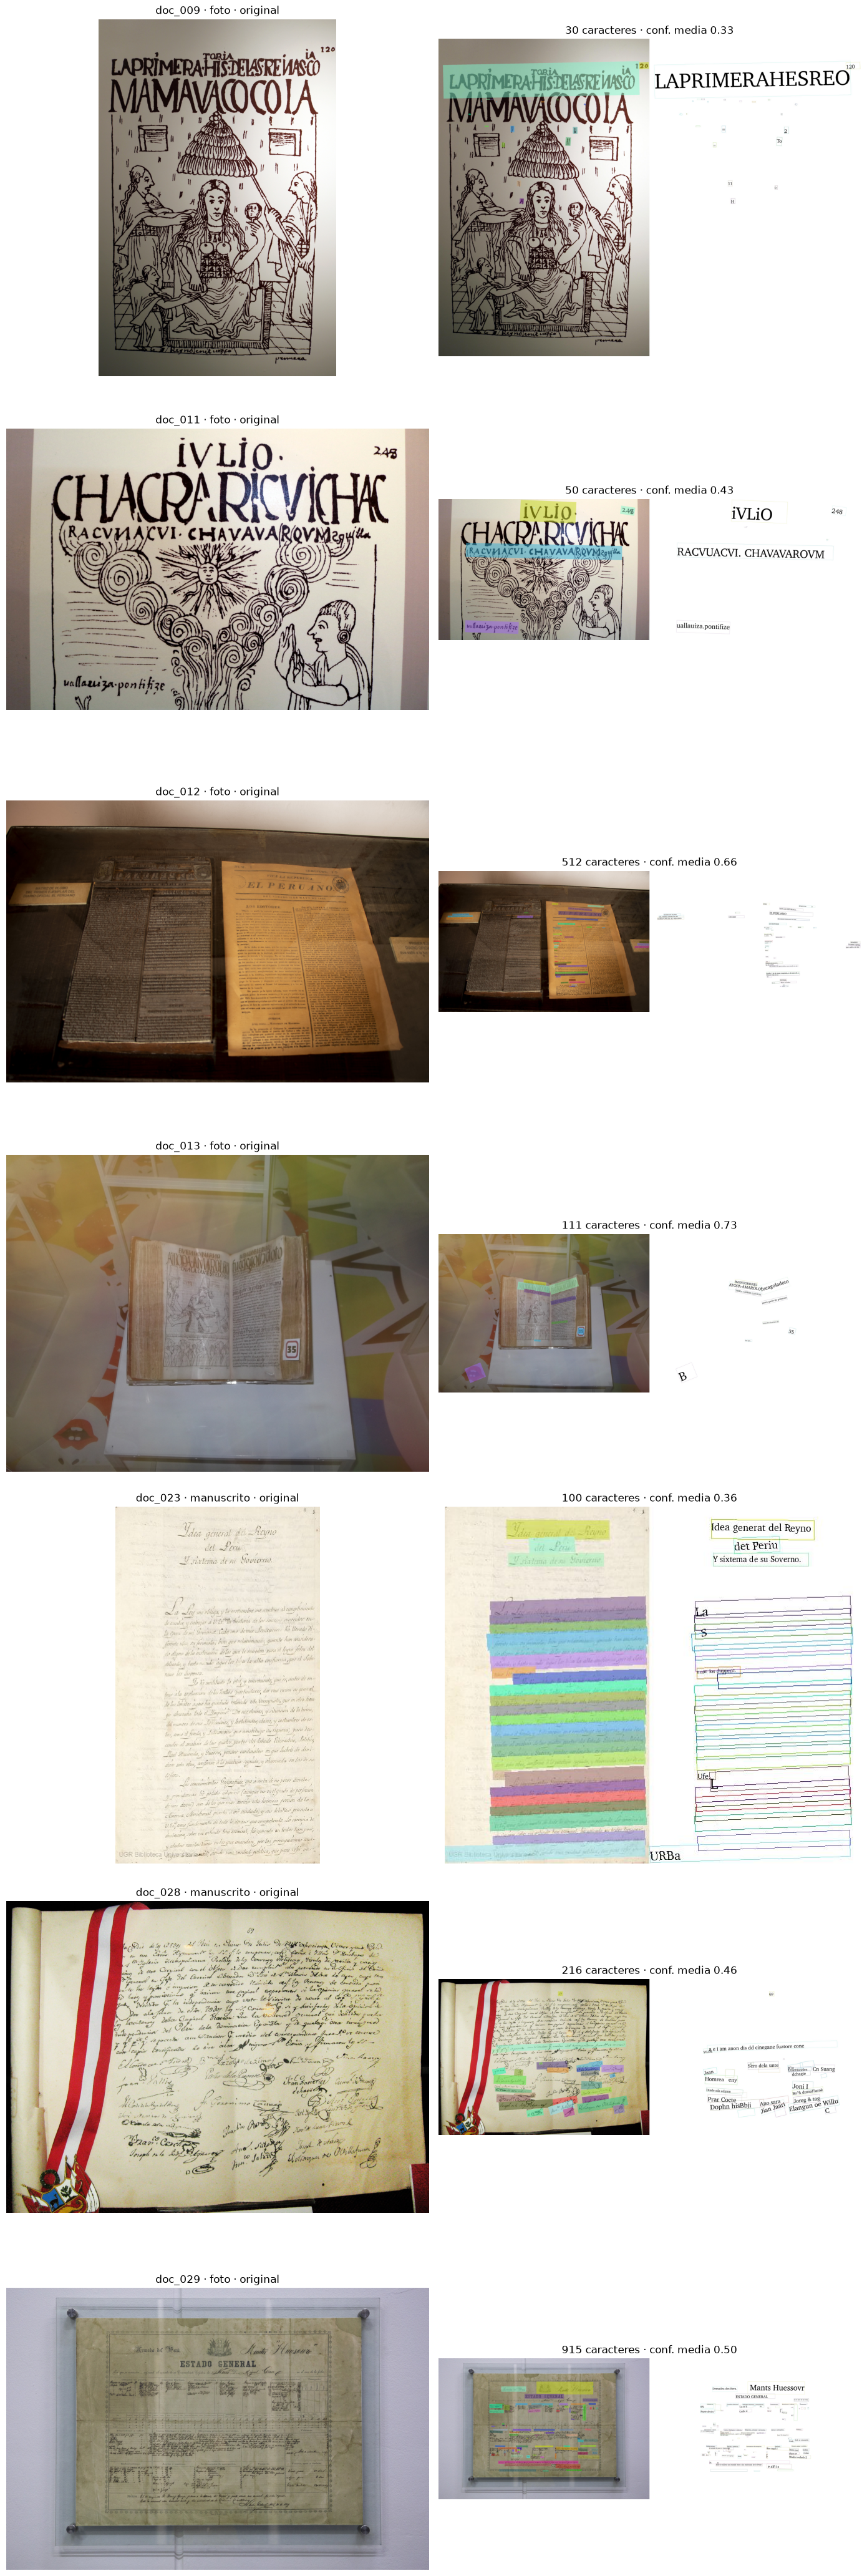

── doc_009 ──
a | = | = | 11 | H | 120 | − | 7 | 2 | To | 0 | LAPRIMERAHESREO 

── doc_011 ──
iVLiO | 248 | 1 | RACVUACVI. CHAVAVAROVM | uallauiza.pontifize 

── doc_012 ──
U | MATRIZ DE PLOMO | DEL PRIMER EJEMPLAR DEL | 1EOOI2O | DIARIO OFICIAL EL PERUANO | NUM. | SEMESTRE. | 10 | VIVA LA REPUBLICA. | ELPERUANO | DEL SABADO ISDE MAYO DE IS96 | LOS EDITORES | es po | Uuo. y espers | SKROR.- | en P | deber segrs | ed | tibonnlo lo idns | les públicos. | Pe | gecienes pirddar, | foraledes, lon | PRIMEREJ | la soeda | DIARIO OFICI | produtrs | que salió a la luz | jn | denen | de de | A.m | gugo | wuogeta sin mrre al d | sa de le loin. | He pondo ye le spone aufna, coye armrdo ne my | guoln, l la de nuae mapiaio, y al nme de a | cl m  e i tda oo ca | eb | INTENOL | Maro se Radee | Av aa | Colo | a | punce | Wst 

── doc_013 ──
BVENGOBIERIO | ATOPA-AMAROLO | fucagoladoto | TAMLA CAVESE ELCV3CO | antes quele de golasenn | comodon francisco de | 35 | ind lg1e | B 

── doc_023 ──
Idea generat

In [45]:
import matplotlib.pyplot as plt

# los documentos marcados (y otros que se quieren mirar): original a la izquierda, cajas
# detectadas a la derecha, y el texto leído
EXTRA = ["doc_012", "doc_013"]
marcados = sorted(set(ocr_res.loc[ocr_res["revisar"], "id"]) | set(EXTRA))
fig, ejes = plt.subplots(len(marcados), 2, figsize=(14, 6 * len(marcados)), squeeze=False)
for (eje_orig, eje_cajas), id_ in zip(ejes, marcados):
    fila = ocr_res.set_index("id").loc[id_]
    eje_orig.imshow(Image.open(TAREA / docs.set_index("id").loc[id_, "archivo"]))
    eje_orig.set_title(f"{id_} · {fila['tipo']} · original")
    vis = sorted(CRUDO.glob(f"{id_}_ocr_res_img.*"))
    if vis:
        eje_cajas.imshow(Image.open(vis[0]))
    eje_cajas.set_title(f"{fila['n_caracteres']} caracteres · conf. media {fila['conf_media']:.2f}")
    for eje in (eje_orig, eje_cajas):
        eje.axis("off")
plt.tight_layout()
plt.show()

for id_ in marcados:
    texto = ocr_res.set_index("id").loc[id_, "texto_ocr"]
    print(f"── {id_} ──")
    print(" | ".join(l.strip() for l in str(texto).splitlines() if l.strip()), "\n")

### Decisión sobre los documentos revisados

Se revisaron a mano los tres documentos marcados por la regla (doc_009, doc_011, doc_023) y, además, doc_012 y doc_013, comparando cada imagen con el texto que leyó el OCR. La revisión se hizo en cuatro rondas: en la primera solo se descartó doc_023; en la segunda, al redactar las observaciones del OCR, se decidió descartar también doc_012; en la tercera, al preparar la muestra de evaluación de `02_evaluacion.ipynb`, se descartó doc_024; en la cuarta, durante la auditoría de las extracciones del LLM en ese mismo notebook, se descartó doc_013.

| Documento | Tipo | Decisión | Motivo |
|---|---|---|---|
| doc_009 | foto | **Se queda** | Lámina de Guamán Poma: casi todo es dibujo, pero el título se reconoce en parte (`LAPRIMERA…`) |
| doc_011 | foto | **Se queda** | Lámina de Guamán Poma: se reconoce parte del título (`iVLiO`, `RACVUACVI. CHAVAVAROVM`) |
| doc_012 | foto | **Se descarta** (2.ª revisión) | **Casi ilegible.** *El Peruano* n.° 1 tras el vidrio de una vitrina, con reflejos: el OCR lee los títulos (`DIARIO OFICIAL EL PERUANO`, `VIVA LA REPUBLICA`), pero el cuerpo del periódico sale como fragmentos sin sentido (`gecienes pirddar`, `wuogeta sin mrre`). 512 caracteres, confianza media 0,66 |
| doc_013 | foto | **Se descarta** (4.ª revisión) | **Ilegible.** En la primera revisión se quedó porque había partes de texto reconocibles, pero la *Nueva corónica* abierta ocupa una parte pequeña de la foto, tomada de lejos tras el vidrio de la vitrina. El OCR solo da fragmentos sin sentido (119 caracteres, confianza media 0,73) y el texto de las páginas no se puede leer a simple vista. Al auditar la extracción del LLM se comprobó que con ese texto no se puede verificar ningún campo |
| doc_024 | manuscrito | **Se descarta** (3.ª revisión) | **Letras desvanecidas.** Es la fotocopia de una partida de bautismo de 1897, de solo 720 × 395 px, con la tinta muy clara: el OCR lee 23 líneas con confianza media de 0,65 y los nombres salen deformados. Tampoco se puede transcribir a mano con seguridad, así que no serviría como referencia para el CER |
| doc_023 | manuscrito | **Se descarta** | **Ilegible.** La imagen mide solo 329 px de ancho: el OCR detecta las líneas pero no puede leerlas (100 caracteres, confianza media 0,36), y tampoco se leen a simple vista |

La baja confianza de las fotos se mantiene como resultado: es justamente la dificultad que el corpus debe mostrar (inclinación, reflejos, dibujos).

**Reemplazo.** Al descartar doc_023 quedaban 8 manuscritos, uno menos que el mínimo de 9. Se reemplazó por **`doc_026`**:

| | Documento descartado | Documento de reemplazo |
|---|---|---|
| Id | `doc_023` | `doc_026` |
| Tipo | manuscrito | manuscrito |
| Obra | *Idea general del Reino del Perú y sistema de su gobierno* (manuscrito, s. XVIII), página de texto | *Relación. Provincia de Saña, Reyno del Perú. Situación local* (fines del s. XVIII), folios 23 y 24: lista de ciudades, provincias y misiones de los obispados de La Paz, Santa Cruz, Paraguay, Tucumán, Buenos Aires y Santiago de Chile |
| Fuente | Biblioteca de la Universidad de Granada, vía Wikimedia Commons (`?curid=89588750`) | Bibliothèque nationale de France, Gallica `btv1b10874724p`, imagen 14 de 15, vía Wikimedia Commons (`?curid=150735557`) |
| Licencia | CC BY-SA 3.0 | Dominio público |
| Imagen | 329 × 573 px | 3840 × 2645 px (reducida desde el original) |

**Reemplazo de doc_012.** Al descartarlo quedaban 7 fotos, una menos que el mínimo de 8. Se reemplazó por **`doc_027`**, elegido entre cuatro fotos de documentos en Commons por tener texto impreso legible, sombra e inclinación reales, y ningún nombre de persona:

| | Documento descartado | Documento de reemplazo |
|---|---|---|
| Id | `doc_012` | `doc_027` |
| Tipo | foto | foto |
| Contenido | Primer número de *El Peruano* (1825) exhibido en una vitrina, con reflejos y sombra | Panel informativo de la Huaca Melgarejo (Municipalidad de La Molina, Lima), en castellano e inglés, fotografiado al sol con sombra e inclinación |
| Fuente | Wikimedia Commons (`?curid=73178570`), autor Id hiroki | Wikimedia Commons (`?curid=124562195`), autora Rocio Nury Jara Jala (2022) |
| Licencia | CC BY-SA 4.0 | CC BY-SA 4.0 |
| Imagen | 3840 × 2560 px | 3024 × 4032 px |

**Reemplazo de doc_024.** Al descartarlo quedaban 8 manuscritos, uno menos que el mínimo de 9. Se reemplazó por **`doc_028`**, elegido entre cinco manuscritos peruanos de Commons (categorías *Baptism certificates of Peru* y *Act of independence of Peru*). Tiene buena resolución, un cuerpo de texto manuscrito legible y no repite la *Relación de Saña*. Las firmas son de los vecinos de Lima que juraron la independencia en 1821, figuras públicas e históricas, así que no se seudonimizan:

| | Documento descartado | Documento de reemplazo |
|---|---|---|
| Id | `doc_024` | `doc_028` |
| Tipo | manuscrito | manuscrito |
| Contenido | Asiento de una partida de bautismo de la parroquia de San Clemente de Pisco (1897), fotocopia | *Acta de la Independencia del Perú* (Lima, 15 de julio de 1821), foto de la edición facsimilar exhibida con una cinta bicolor: cuerpo del acta y firmas |
| Fuente | Wikimedia Commons (`?curid=190398555`) | Wikimedia Commons (`?curid=18644878`), autor Murillo Perú (2012) |
| Licencia | Dominio público | CC BY-SA 3.0 |
| Imagen | 720 × 395 px | 2492 × 1838 px |

**Reemplazo de doc_013.** Al descartarlo quedaban 7 fotos, una menos que el mínimo de 8. Se reemplazó por **`doc_029`**, elegido entre las fotos de documentos de Commons revisadas para `doc_012` por ser el más parecido a `doc_013`: un documento antiguo fotografiado en una exhibición tras un vidrio, con brillo y papel envejecido. Combina texto impreso legible (encabezados del formulario) con texto manuscrito de 1879. Miguel Grau es figura pública; si el OCR lee los nombres de otros tripulantes, se seudonimizan como las personas de los demás documentos históricos:

| | Documento descartado | Documento de reemplazo |
|---|---|---|
| Id | `doc_013` | `doc_029` |
| Tipo | foto | foto |
| Contenido | *Nueva corónica y buen gobierno* abierta en una vitrina de la Biblioteca Real de Dinamarca, fotografiada de lejos | *Estado General* del monitor *Huáscar* (Armada del Perú, 1879), formulario impreso llenado a mano, enmarcado tras un vidrio en una exhibición |
| Fuente | Wikimedia Commons (`?curid=22888046`), autor Palnatoke | Wikimedia Commons (`?curid=153256484`), autor Ministerio de Defensa del Perú (2024) |
| Licencia | CC BY-SA 3.0 | CC BY 2.0 |
| Imagen | 3664 × 2748 px | 3840 × 2560 px (reducida desde 5223 × 3482) |

`doc_026`, `doc_027`, `doc_028` y `doc_029` se descargaron con el mismo procedimiento que el resto, se procesan con el mismo OCR y los mismos parámetros, y no se usaron para ajustar nada. Los descartados quedan registrados en `datos/fuentes.csv` con `descartado=True` y su motivo.

In [46]:
# documentos descartados tras la revisión manual (se reportan y se reemplazan)
DESCARTADOS = {
    "doc_023": "Ilegible: imagen de 329 px de ancho; el OCR detecta las líneas pero no puede leerlas",
    "doc_012": "Casi ilegible: reflejos de la vitrina; el OCR solo lee los títulos y fragmentos sueltos del cuerpo",
    "doc_024": "Letras desvanecidas: fotocopia de 720 px de ancho; el OCR lee pocas líneas y con baja confianza",
    "doc_013": "Ilegible: la Nueva corónica ocupa una parte pequeña de la foto, tomada de lejos tras el vidrio; el OCR solo da fragmentos",
}
REEMPLAZOS = {"doc_023": "doc_026", "doc_012": "doc_027", "doc_024": "doc_028", "doc_013": "doc_029"}  # descartado -> documento del mismo tipo que lo reemplaza
ocr_res["descartado"] = ocr_res["id"].isin(DESCARTADOS)
ocr_res["motivo_descarte"] = ocr_res["id"].map(DESCARTADOS).fillna("")

print("Descartados:")
print(ocr_res.loc[ocr_res["descartado"], ["id", "tipo", "n_caracteres", "conf_media", "motivo_descarte"]].to_string(index=False))

print("\nReemplazos:")
info = fuentes.set_index("id")
for viejo, nuevo in REEMPLAZOS.items():
    r = ocr_res.set_index("id").loc[nuevo]
    print(f"  {viejo} -> {nuevo} ({info.loc[nuevo, 'tipo']}): {info.loc[nuevo, 'descripcion']}")
    print(f"     {info.loc[nuevo, 'fuente_url']} · {info.loc[nuevo, 'licencia']} · OCR: {r['n_caracteres']} caracteres, conf. media {r['conf_media']:.2f}")

MINIMOS = {"impreso": 8, "foto": 8, "manuscrito": 9}
validos = ocr_res.loc[~ocr_res["descartado"]].groupby("tipo").size()
print("\nDocumentos válidos por tipo:")
for tipo, minimo in MINIMOS.items():
    n = int(validos.get(tipo, 0))
    print(f"  {tipo:10} {n:2d} de {minimo}  {'ok' if n >= minimo else f'FALTA {minimo - n}: reemplazar'}")

Descartados:
     id       tipo  n_caracteres  conf_media                                                                                                           motivo_descarte
doc_012       foto           512       0.655                        Casi ilegible: reflejos de la vitrina; el OCR solo lee los títulos y fragmentos sueltos del cuerpo
doc_013       foto           111       0.734 Ilegible: la Nueva corónica ocupa una parte pequeña de la foto, tomada de lejos tras el vidrio; el OCR solo da fragmentos
doc_023 manuscrito           100       0.361                                      Ilegible: imagen de 329 px de ancho; el OCR detecta las líneas pero no puede leerlas
doc_024 manuscrito           584       0.652                           Letras desvanecidas: fotocopia de 720 px de ancho; el OCR lee pocas líneas y con baja confianza

Reemplazos:
  doc_023 -> doc_026 (manuscrito): Relación de la Provincia de Saña (fines del s. XVIII): lista de ciudades y provincias a dos páginas
    

### Observaciones del OCR

**Impresos: el mejor resultado.** La confianza media va de 0,94 a 0,99. La página de *El Peruano* de 1844 (`doc_008`) es la más baja del grupo: tiene tipografía antigua y tres columnas. Como el orden de lectura solo separa dos mitades de la página, el texto de las columnas se mezcla. Las palabras se leen bien, pero esto afectará el CER si `doc_008` entra en la muestra de evaluación.

**Fotos: el grupo más desigual** (confianza de 0,33 a 0,98). Hay partes del texto legibles y otras no, según lo que se fotografió:

- **Carteles y paneles impresos** (`doc_015`, `doc_016`, `doc_027`): se leen casi completos (0,97–0,98), aunque tengan perspectiva, sombra o brillo. Aun así hay errores de detección. En `doc_027` el OCR pierde la letra capitular («uaca Melgarejo» en lugar de «Huaca Melgarejo») y se salta una línea entera del párrafo sobre la Guerra del Pacífico.
- **Documentos antiguos tras el vidrio de una vitrina** (`doc_009`–`doc_011`, `doc_014`, `doc_029`): solo se reconocen títulos y fragmentos (0,33–0,83).
  - En las láminas de la *Nueva corónica* de Guamán Poma hay además **español antiguo y quechua**, que ningún diccionario moderno corregiría.
  - Pero **el idioma no es la causa principal**. PaddleOCR no tiene un modelo «solo de español»: `lang="es"` carga el reconocedor latino (`latin_PP-OCRv5_mobile_rec`), compartido por unos 40 idiomas que usan el alfabeto latino, entre ellos el quechua (`lang="qu"` carga exactamente el mismo modelo). El reconocedor lee carácter por carácter, sin vocabulario de palabras.
  - Lo que falla es la imagen: **letra manuscrita de 1615**, con abreviaturas y formas de letra que el modelo casi no vio al entrenarse, texto corto dentro de los dibujos, y reflejos e inclinación del vidrio.

**Manuscritos: intermedio, con el caso más bajo del corpus válido** (0,46–0,95).
- Las páginas de la *Relación de la Provincia de Saña* (BnF) dan 0,59–0,69, salvo la lista de ciudades de `doc_026` (0,95), que tiene letra más espaciada y regular.
- La *Relación de antigüedades* de 1613 (`doc_022`) da 0,58: letra del s. XVII con dibujos intercalados.
- El *Acta de la Independencia* (`doc_028`) es la más baja (0,46, solo 216 caracteres en 29 líneas), aunque se lee bien a simple vista. El detector **no encuentra casi ninguno de los 15 renglones del cuerpo**: la letra cursiva es apretada e inclinada, y la imagen de 2492 px se reduce a 1920 px antes de detectar (límite fijado en el paso 2.1). Solo detecta las firmas, aisladas y más grandes, y las lee deformadas. No es un documento ilegible sino un fallo del modelo, así que se mantiene como caso difícil para `02_evaluacion.ipynb`, donde se compara con PaddleOCR sin ese límite y con Tesseract.
- En la partida de bautismo del s. XVIII (`doc_025`), los nombres propios salen deformados. Por eso el diccionario de seudonimización incluye esas variantes mal escritas.

**Descartes y reemplazos.**
- `doc_023` se descartó por ilegible (329 px de ancho) y lo reemplaza `doc_026`.
- `doc_012` se descartó en una segunda revisión: los reflejos de la vitrina dejan solo los títulos legibles. Lo reemplaza `doc_027`.
- `doc_013` se descartó en una cuarta revisión, durante la auditoría del LLM: la *Nueva corónica* sale demasiado pequeña y lejana en la foto, y su texto no se puede leer. Lo reemplaza `doc_029`.
- `doc_024` se descartó en una tercera revisión porque sus letras están desvanecidas (fotocopia de 720 px). Lo reemplaza `doc_028`.
- El corpus mantiene 8 impresos, 8 fotos y 9 manuscritos.

## 3. ASR: transcripción de las entrevistas (sesión 13)

Pasos para los 22 clips (35,0 min): **VAD** → **transcripción con faster-whisper** → **diarización** → exportación a **CSV, SRT y TXT**.

### Modelo y parámetros

| Parámetro | Valor | Por qué |
|---|---|---|
| Modelo | Whisper large-v3-turbo en CTranslate2 (`mobiuslabsgmbh/faster-whisper-large-v3-turbo`), el mismo `faster-whisper` de `voz.py` | Es el que mejor transcribe español de los que corren en CPU. Tiene solo 4 capas de decodificador, así que es mucho más rápido que large-v3 |
| `compute_type` | `int8` en CPU | Ocupa más o menos la mitad de memoria que `float16` y es más rápido en CPU |
| `cpu_threads` | la mitad de los núcleos, máximo 4 | **Deja la otra mitad libre para seguir usando la laptop** |
| `language` | `"es"` | Fijo: no se gasta tiempo detectando el idioma y se evita que cambie de idioma en el ruido |
| `beam_size` | 5 | Igual que en `voz.py` |
| `vad_filter` | `True`, silencios de 0,3 s (Silero VAD) | No le pasa silencio, música ni ruido al modelo: así se evitan las frases inventadas |
| `condition_on_previous_text` | `False` | Evita que una frase mal reconocida se repita en bucle en los segmentos siguientes |
| Diarización | WeSpeaker ResNet34 (`pyannote/wespeaker-voxceleb-resnet34-LM`) + clustering jerárquico con umbral 0,7, en CPU | Lo mismo que `voz.diarizar`. El modelo de huellas de voz es pequeño |

### Para que la laptop siga usable mientras corre

- Se transcribe **un clip a la vez** y el resultado se guarda apenas termina cada clip. Si se interrumpe la celda, al volver a ejecutarla **continúa donde quedó**.
- Whisper y el modelo de diarización **no están en memoria al mismo tiempo**: primero se transcribe todo, se libera Whisper y recién después se diariza.
- Tanto faster-whisper como torch usan solo `HILOS` núcleos.

### Qué se guarda en `datos/raw/audio/` (fuera de Git)

- `originales/clip_XXX.*`: el audio tal como vino de Commons (ogg, opus o wav).
- `clip_XXX.wav`: la versión mono de 16 kHz que reciben los modelos.
- `asr/clip_XXX_segmentos.json`: respaldo crudo de Whisper, con cada segmento, sus tiempos y sus métricas de confianza.
- `asr/clip_XXX.csv`, `asr/clip_XXX.srt` y `asr/clip_XXX.txt`: segmentos con hablante, subtítulos y transcripción para leer.
- `asr/asr_resultados.csv`: tabla resumen.

In [47]:
# 3.1 VAD: ¿todos los clips tienen voz? (mismo criterio que al descargar)
audios = fuentes[fuentes["corpus"] == "audio"][["id", "archivo", "descartado", "motivo_descarte"]].reset_index(drop=True)
vad = pd.DataFrame([{"id": a.id, **revisar_voz(cargar_audio(TAREA / a.archivo))} for a in audios.itertuples()])
vad = vad.merge(audios[["id", "descartado", "motivo_descarte"]], on="id")
print(vad[["id", "duracion_seg", "segundos_voz", "proporcion_voz", "tiene_voz"]].to_string(index=False))

print("\nDescartados:")
print(vad.loc[~vad["tiene_voz"], ["id", "motivo_descarte"]].to_string(index=False))
validos_audio = vad.loc[vad["tiene_voz"], "id"].tolist()
print(f"\nClips válidos: {len(validos_audio)} (mínimo 20) · "
      f"{vad.loc[vad['tiene_voz'], 'duracion_seg'].sum() / 60:.1f} min de audio (mínimo 30), "
      f"{vad.loc[vad['tiene_voz'], 'segundos_voz'].sum() / 60:.1f} min con voz")

      id  duracion_seg  segundos_voz  proporcion_voz  tiene_voz
clip_001        189.01        154.51           0.817       True
clip_002        136.30        105.51           0.774       True
clip_003         29.93         27.27           0.911       True
clip_004         20.15         13.63           0.676       True
clip_005        196.03        176.74           0.902       True
clip_006         96.13         82.10           0.854       True
clip_007         77.44         67.38           0.870       True
clip_008        163.90        140.57           0.858       True
clip_009         48.25         35.26           0.731       True
clip_010         54.26         50.79           0.936       True
clip_011         77.35         70.43           0.911       True
clip_012         95.04         67.73           0.713       True
clip_013         81.60         78.44           0.961       True
clip_014         98.26         10.62           0.108      False
clip_015         39.24         37.85    

**Audio sin voz descartado.** `clip_014` (entrevista en la fiesta de Tayta Palli de Chuyas, Lima, 2024) está saturado: tiene picos en el máximo de la señal y, según el VAD, solo 10,6 s de voz en 98 s, el 11 %. El resto parece música o ruido de fiesta, donde Whisper inventa frases. Se descarta y lo reemplaza `clip_022` (testimonio del proyecto *Salas, pantallas y archivos*, CC BY 4.0). Con eso quedan 21 clips válidos y 35,0 min de audio. `clip_014` queda registrado en `datos/fuentes.csv` con `descartado=True` y no se transcribe.

In [48]:
# 3.2 Modelo de ASR, con pocos hilos para que la laptop siga usable
import gc
import json
import os
import time

import torch
from faster_whisper import WhisperModel

# si el OCR del paso 2 sigue en memoria, se libera antes de cargar Whisper
if "ocr" in globals():
    del ocr
    gc.collect()

HILOS = max(1, min(4, (os.cpu_count() or 4) // 2))
torch.set_num_threads(HILOS)

AUDIO = RAW / "audio"
ASR = AUDIO / "asr"
ASR.mkdir(parents=True, exist_ok=True)
REHACER_ASR = False  # True para volver a transcribir todos los clips

MODELO_HF = "mobiuslabsgmbh/faster-whisper-large-v3-turbo"
PARAMS_ASR = dict(language="es", beam_size=5, vad_filter=True,
                  vad_parameters={"min_silence_duration_ms": 300}, condition_on_previous_text=False)
MODELO_ASR = (f"faster-whisper {md.version('faster-whisper')} · Whisper large-v3-turbo ({MODELO_HF}), int8, "
              f"CPU {HILOS} hilos, beam 5, language=es, VAD Silero on (silencio 0,3 s), "
              f"condition_on_previous_text=False · diarización WeSpeaker ResNet34 + clustering (umbral 0,7)")

t0 = time.perf_counter()
whisper = WhisperModel(MODELO_HF, device="cpu", compute_type="int8", cpu_threads=HILOS, num_workers=1)
print(f"Whisper cargado en {time.perf_counter() - t0:.1f} s con {HILOS} hilos de {os.cpu_count()} núcleos")
print(MODELO_ASR)

Whisper cargado en 3.0 s con 3 hilos de 6 núcleos
faster-whisper 1.2.1 · Whisper large-v3-turbo (mobiuslabsgmbh/faster-whisper-large-v3-turbo), int8, CPU 3 hilos, beam 5, language=es, VAD Silero on (silencio 0,3 s), condition_on_previous_text=False · diarización WeSpeaker ResNet34 + clustering (umbral 0,7)


In [49]:
# ── Extraído de voz.py (sesión 13, Data-Science-Python) ───────────────────────────────
from dataclasses import asdict, dataclass
from functools import lru_cache


@dataclass
class Segmento:
    inicio: float
    fin: float
    texto: str
    hablante: str | None = None


@lru_cache(maxsize=1)
def _modelo_de_voces(device: str):
    """WeSpeaker ResNet34: convierte un tramo de voz en un vector de 256 números (la 'huella' de la voz)."""
    import torch
    from pyannote.audio import Inference, Model
    modelo = Model.from_pretrained("pyannote/wespeaker-voxceleb-resnet34-LM")
    return Inference(modelo, window="whole", device=torch.device(device))


def huellas_de_voz(audio: np.ndarray, tramos: list[tuple[float, float]], device: str | None = None) -> np.ndarray:
    """Un vector por tramo. Dos tramos de la misma persona dan vectores parecidos (coseno alto)."""
    import torch
    inf = _modelo_de_voces(device or "cpu")
    filas = []
    for a, b in tramos:
        x = audio[int(a * SR):int(b * SR)]
        if len(x) < SR // 2:  # el modelo necesita al menos medio segundo
            x = np.pad(x, (0, SR // 2 - len(x)))
        filas.append(inf({"waveform": torch.from_numpy(x).unsqueeze(0), "sample_rate": SR}))
    return np.vstack(filas)


def diarizar(audio: np.ndarray, segmentos: list[Segmento], n_hablantes: int | None = None,
             umbral: float = 0.7, min_dur: float = 1.0, device: str | None = None) -> list[Segmento]:
    """Pone nombre de hablante (H1, H2...) a cada segmento.

    1. Huella de voz de cada segmento.
    2. Agrupa las huellas (clustering jerárquico con distancia coseno). Si no sabes cuántas
       personas hay, el `umbral` decide cuándo dos voces son distintas.
    3. Los segmentos muy cortos (<1 s: "sí", "ajá") dan huellas poco fiables: no votan en el
       agrupamiento y después se asignan al grupo más parecido.
    """
    from sklearn.cluster import AgglomerativeClustering
    if not segmentos:
        return []
    E = huellas_de_voz(audio, [(s.inicio, s.fin) for s in segmentos], device)
    E = E / np.linalg.norm(E, axis=1, keepdims=True)
    largos = np.array([s.fin - s.inicio >= min_dur for s in segmentos])
    if largos.sum() < 2:
        largos[:] = True
    if n_hablantes == 1 or largos.sum() < 2:
        etiquetas = np.zeros(len(segmentos), dtype=int)
    else:
        grupo = AgglomerativeClustering(n_clusters=n_hablantes, distance_threshold=None if n_hablantes else umbral,
                                        metric="cosine", linkage="average").fit(E[largos])
        centros = np.vstack([E[largos][grupo.labels_ == k].mean(axis=0) for k in range(grupo.n_clusters_)])
        etiquetas = (E @ centros.T).argmax(axis=1)
        etiquetas[largos] = grupo.labels_
    # numerar por orden de aparición: H1 es quien habla primero (en una entrevista, casi siempre quien entrevista)
    orden = {k: i + 1 for i, k in enumerate(dict.fromkeys(etiquetas))}
    return [Segmento(s.inicio, s.fin, s.texto, f"H{orden[e]}") for s, e in zip(segmentos, etiquetas)]


def a_tabla(segmentos: list[Segmento]) -> pd.DataFrame:
    return pd.DataFrame([asdict(s) for s in segmentos], columns=["inicio", "fin", "hablante", "texto"])


def _hhmmss(t: float, sep=",") -> str:
    h, r = divmod(t, 3600)
    m, s = divmod(r, 60)
    return f"{int(h):02d}:{int(m):02d}:{int(s):02d}{sep}{int(round((s % 1) * 1000)):03d}"


def a_srt(segmentos: list[Segmento]) -> str:
    """Subtítulos SRT: los abren VLC, YouTube, ELAN, Atlas.ti, MAXQDA y NVivo."""
    bloques = []
    for i, s in enumerate(segmentos, 1):
        quien = f"[{s.hablante}] " if s.hablante else ""
        bloques.append(f"{i}\n{_hhmmss(s.inicio)} --> {_hhmmss(s.fin)}\n{quien}{s.texto}\n")
    return "\n".join(bloques)


def a_texto(segmentos: list[Segmento]) -> str:
    """Transcripción para leer: une segmentos seguidos del mismo hablante en un solo turno."""
    turnos = []
    for s in segmentos:
        if turnos and turnos[-1][1] == s.hablante:
            turnos[-1][2].append(s.texto)
        else:
            turnos.append([s.inicio, s.hablante, [s.texto]])
    return "\n\n".join(f"[{_hhmmss(t, '.')[:8]}] {h + ': ' if h else ''}{' '.join(x)}" for t, h, x in turnos)

In [50]:
# 3.3 Transcripción de un clip (equivalente a Transcriptor('faster-whisper').segmentos de voz.py,
# pero guardando también las métricas de cada segmento para revisar alucinaciones)
def transcribir_clip(id_, ruta):
    audio = cargar_audio(ruta)
    t0 = time.perf_counter()
    segs, info = whisper.transcribe(audio, **PARAMS_ASR)
    segmentos = [{"inicio": round(s.start, 2), "fin": round(s.end, 2), "texto": s.text.strip(),
                  "avg_logprob": round(s.avg_logprob, 3), "no_speech_prob": round(s.no_speech_prob, 3),
                  "compression_ratio": round(s.compression_ratio, 2)}
                 for s in segs if s.text.strip()]  # el generador transcribe a medida que se recorre
    crudo = {"id": id_, "archivo": str(Path(ruta).relative_to(TAREA)), "modelo_asr": MODELO_ASR,
             "idioma": info.language, "duracion_seg": round(len(audio) / SR, 2),
             "segundos_proceso": round(time.perf_counter() - t0, 1), "segmentos": segmentos}
    (ASR / f"{id_}_segmentos.json").write_text(json.dumps(crudo, ensure_ascii=False, indent=1), encoding="utf-8")
    return crudo


def texto_con_hablantes(segmentos):
    # '[HABLANTE_1] ... [HABLANTE_2] ...': une segmentos seguidos de la misma persona en un turno
    turnos = []
    for s in segmentos:
        if turnos and turnos[-1][0] == s.hablante:
            turnos[-1][1].append(s.texto)
        else:
            turnos.append([s.hablante, [s.texto]])
    return "\n".join(f"[HABLANTE_{h[1:]}] {' '.join(t)}" for h, t in turnos)

In [51]:
# 3.4 Transcribir los clips válidos, uno a la vez (se puede interrumpir y retomar)
archivo_de = audios.set_index("id")["archivo"]
for id_ in validos_audio:
    if (ASR / f"{id_}_segmentos.json").exists() and not REHACER_ASR:
        print(f"{id_} ya estaba")
        continue
    crudo = transcribir_clip(id_, TAREA / archivo_de[id_])
    velocidad = crudo["duracion_seg"] / crudo["segundos_proceso"]
    print(f"{id_} {crudo['duracion_seg']:6.1f} s de audio en {crudo['segundos_proceso']:6.1f} s "
          f"({velocidad:.1f}x tiempo real) · {len(crudo['segmentos'])} segmentos")

# liberar Whisper antes de cargar el modelo de diarización
del whisper
gc.collect()

clip_001 ya estaba
clip_002 ya estaba
clip_003 ya estaba
clip_004 ya estaba
clip_005 ya estaba
clip_006 ya estaba
clip_007 ya estaba
clip_008 ya estaba
clip_009 ya estaba
clip_010 ya estaba
clip_011 ya estaba
clip_012 ya estaba
clip_013 ya estaba
clip_015 ya estaba
clip_016 ya estaba
clip_017 ya estaba
clip_018 ya estaba
clip_019 ya estaba
clip_020 ya estaba
clip_021 ya estaba
clip_022 ya estaba


20

### Diarización y exportación

Se diariza **cada clip válido** con el umbral de `voz.diarizar` (0,7) y sin fijar el número de hablantes, porque `transcripciones.csv` pide `n_hablantes` para todos los clips. El caso de prueba es `clip_001`: según su descripción en Commons, ahí hablan **tres personas** (quien entrevista y dos vendedoras de dulces en El Agustino). H1 es quien habla primero.

In [52]:
# 3.5 Diarización (CPU, HILOS núcleos) y exportación a CSV, SRT y TXT
filas = []
for id_ in validos_audio:
    crudo = json.loads((ASR / f"{id_}_segmentos.json").read_text(encoding="utf-8"))
    segs = [Segmento(s["inicio"], s["fin"], s["texto"]) for s in crudo["segmentos"]]
    if not (ASR / f"{id_}.csv").exists() or REHACER_ASR:
        segs = diarizar(cargar_audio(TAREA / archivo_de[id_]), segs, device="cpu")
        a_tabla(segs).to_csv(ASR / f"{id_}.csv", index=False)
        (ASR / f"{id_}.srt").write_text(a_srt(segs), encoding="utf-8")
        (ASR / f"{id_}.txt").write_text(a_texto(segs), encoding="utf-8")
    tabla = pd.read_csv(ASR / f"{id_}.csv").fillna({"texto": ""})
    segs = [Segmento(r.inicio, r.fin, r.texto, r.hablante) for r in tabla.itertuples()]
    metricas = pd.DataFrame(crudo["segmentos"])
    filas.append({"id": id_, "duracion_seg": crudo["duracion_seg"], "idioma": crudo["idioma"],
                  "segundos_proceso": crudo["segundos_proceso"], "n_segmentos": len(segs),
                  "n_hablantes": tabla["hablante"].nunique(),
                  "logprob_media": round(metricas["avg_logprob"].mean(), 3) if len(metricas) else None,
                  "texto_asr": texto_con_hablantes(segs), "modelo_asr": crudo["modelo_asr"]})
    print(f"{id_}: {filas[-1]['n_hablantes']} hablante(s), {len(segs)} segmentos")

asr_res = pd.DataFrame(filas)
asr_res.to_csv(ASR / "asr_resultados.csv", index=False)
print(f"\nTranscritos: {len(asr_res)} clips · {asr_res['duracion_seg'].sum() / 60:.1f} min de audio "
      f"en {asr_res['segundos_proceso'].sum() / 60:.1f} min de proceso")

clip_001: 3 hablante(s), 36 segmentos
clip_002: 2 hablante(s), 25 segmentos
clip_003: 2 hablante(s), 4 segmentos
clip_004: 2 hablante(s), 4 segmentos
clip_005: 3 hablante(s), 63 segmentos
clip_006: 2 hablante(s), 15 segmentos
clip_007: 2 hablante(s), 15 segmentos
clip_008: 2 hablante(s), 41 segmentos
clip_009: 4 hablante(s), 17 segmentos
clip_010: 3 hablante(s), 11 segmentos
clip_011: 2 hablante(s), 29 segmentos
clip_012: 9 hablante(s), 42 segmentos
clip_013: 1 hablante(s), 13 segmentos
clip_015: 1 hablante(s), 2 segmentos
clip_016: 1 hablante(s), 7 segmentos
clip_017: 1 hablante(s), 6 segmentos
clip_018: 1 hablante(s), 20 segmentos
clip_019: 1 hablante(s), 84 segmentos
clip_020: 2 hablante(s), 24 segmentos
clip_021: 3 hablante(s), 94 segmentos
clip_022: 1 hablante(s), 20 segmentos

Transcritos: 21 clips · 35.0 min de audio en 19.8 min de proceso


In [53]:
# 3.6 Resultado de la diarización (solo números: el texto se muestra en el paso 5, ya seudonimizado)
CLIP_VISTA = "clip_001"  # el clip con tres personas
print(f"{CLIP_VISTA}: " + asr_res.set_index("id").loc[CLIP_VISTA, ["duracion_seg", "n_segmentos", "n_hablantes"]]
      .to_string().replace("\n", " · "))

print("\nHablantes detectados por clip:")
asr_res["n_hablantes"].value_counts().sort_index().rename_axis("n_hablantes").rename("clips")

clip_001: duracion_seg    189.01 · n_segmentos         36 · n_hablantes          3

Hablantes detectados por clip:


n_hablantes
1    7
2    8
3    4
4    1
9    1
Name: clips, dtype: int64

### Verificación de alucinaciones

Aunque se usa el VAD, Whisper puede inventar frases en el ruido. Se marcan para escuchar los segmentos con señales típicas de alucinación (umbrales por defecto de Whisper, no ajustados con los datos):

- `compression_ratio > 2,4`: texto repetitivo.
- `no_speech_prob > 0,6` junto con `avg_logprob < -1`: el modelo cree que no hay voz y además duda del texto.

Además, se revisa a mano una muestra al azar de segmentos, escuchando el audio en esos tiempos.

La lista (segmentos sospechosos y muestra) se guarda con su texto en `datos/raw/audio/asr/revision_alucinaciones.csv`, para escucharla fuera del notebook. Aquí solo se muestran los ids y los tiempos; el texto aparece en el paso 5, ya seudonimizado.

In [54]:
# 3.7 Segmentos sospechosos y muestra al azar para verificar escuchando
# (aquí solo ids y tiempos; el texto se muestra en el paso 5, ya seudonimizado)
segs_todos = pd.concat([pd.DataFrame(json.loads((ASR / f"{i}_segmentos.json").read_text(encoding="utf-8"))["segmentos"])
                        .assign(id=i) for i in validos_audio], ignore_index=True)
sospechosos = segs_todos[(segs_todos["compression_ratio"] > 2.4) |
                         ((segs_todos["no_speech_prob"] > 0.6) & (segs_todos["avg_logprob"] < -1))]
muestra = segs_todos.sample(8, random_state=13)
revision = pd.concat([sospechosos.assign(motivo="sospechoso"), muestra.assign(motivo="muestra al azar")])
revision.to_csv(ASR / "revision_alucinaciones.csv", index=False)  # con el texto, para escuchar y comparar

print(f"Segmentos sospechosos: {len(sospechosos)} de {len(segs_todos)}")
print(f"Lista para escuchar: {(ASR / 'revision_alucinaciones.csv').relative_to(TAREA)}")
revision[["motivo", "id", "inicio", "fin", "compression_ratio", "no_speech_prob", "avg_logprob"]]

Segmentos sospechosos: 0 de 572
Lista para escuchar: datos/raw/audio/asr/revision_alucinaciones.csv


,motivo,id,inicio,fin,compression_ratio,no_speech_prob,avg_logprob
142,muestra al azar,clip_006,67.38,74.72,1.73,0.0,-0.162
326,muestra al azar,clip_017,30.49,35.09,1.60,0.0,-0.108
397,muestra al azar,clip_019,139.49,140.95,1.73,0.0,-0.117
44,muestra al azar,clip_002,38.78,47.22,1.57,0.0,-0.160
374,muestra al azar,clip_019,82.80,84.53,1.89,0.0,-0.093
114,muestra al azar,clip_005,150.50,153.72,1.75,0.0,-0.101
514,muestra al azar,clip_021,116.04,117.94,1.74,0.0,-0.183
101,muestra al azar,clip_005,105.78,108.13,1.57,0.0,-0.127


### Observaciones del ASR

**Alucinaciones.** Ningún segmento cumple las reglas automáticas: 0 sospechosos de 572 (ningún `compression_ratio > 2,4` ni la combinación `no_speech_prob > 0,6` con `avg_logprob < -1`). La muestra al azar de 8 segmentos (`clip_002`, `clip_005` ×2, `clip_006`, `clip_017`, `clip_019` ×2, `clip_021`) se escuchó completa: **no se encontraron alucinaciones**. En todos los casos el texto corresponde a algo que efectivamente se dice en el audio.

**Errores observados al escuchar** (revisión humana):

- **Palabras mal reconocidas.** El modelo oye la palabra pero la cambia por otra parecida. Ejemplo: en `clip_019` (153,2–155,2 s) transcribe *«repilante»* donde se dice *«horripilante»*. El segmento tiene confianza alta (`avg_logprob = -0,08`), así que este tipo de error no lo detectan las métricas: solo se ve escuchando y se medirá con el WER en `02_evaluacion.ipynb`.
- **Omisiones en audio con ruido.** `clip_002` es una entrevista con bulla de fondo. Algunas frases de una de las hablantes, que el oído humano sí distingue, no aparecen en la transcripción. No es posible saber si el VAD las cortó como ruido o si Whisper las omitió. Es lo contrario de una alucinación: falta texto en vez de sobrar.

**Diarización.** En `clip_001` (entrevista con tres personas) WeSpeaker con clustering jerárquico detectó 3 hablantes. Al escuchar el audio, **separa bien las tres voces**: cada turno `[HABLANTE_n]` corresponde a una sola persona.

**Duda sobre `clip_012`.** La diarización detecta **9 hablantes** en 95 s. El audio se titula «Entrevistas en la Marcha del Orgullo», así que pueden ser varias entrevistas cortas seguidas. Pero también es posible que el ruido de la marcha haga que el modelo separe a una misma persona en varias voces. No se verificó escuchando: en `transcripciones.csv` se deja el valor que dio el modelo (`n_hablantes = 9`), y este número debe tomarse como un máximo, no como un conteo confirmado.

**Conclusión.** Con el VAD activado y `condition_on_previous_text=False`, el modelo no inventó texto en la muestra revisada. Los errores son de sustitución de palabras y de omisión en tramos ruidosos.


## 4. Seudonimización de todo el texto extraído (OCR y ASR)

Se hace **después** de extraer todo el texto, sobre los 25 documentos válidos y los 21 clips válidos, y **antes** de publicar cualquier texto en los CSV, el README o el dashboard.

### Criterio: qué se reemplaza

| Dato | Se reemplaza por | Ejemplos |
|---|---|---|
| Nombre de una persona real: entrevistada, mencionada en una entrevista, que firma o aparece en un documento (también funcionarios y personas de documentos históricos) | `[PERSONA_n]`, el mismo número para la misma persona en todo el corpus | firmantes de un decreto, un alcalde, los vecinos de un parte de 1844, los padres y padrinos de una partida de bautismo |
| Pedazo de nombre que el OCR deformó y que no se puede atribuir a nadie | `[NOMBRE]` | firmas y apellidos ilegibles en los manuscritos |
| DNI | `[DNI]` | `DNI 12345678` |
| Teléfono (celular o fijo) | `[TELEFONO]` | `934 369 505`, `(01) 715-9700` |
| Correo electrónico | `[CORREO]` | |

**No se reemplazan:** los personajes históricos citados como tales (por ejemplo, Simón Bolívar como fundador de *El Peruano*), las figuras públicas mencionadas por su papel público en una conversación, que no participan en ella (congresistas nombrados en una arenga, futbolistas, actores), los nombres de personas que forman parte de un lugar o una institución (hospital Edgardo Rebagliati, distrito de San Martín de Porres), los lugares, las instituciones ni las marcas de hablante `[HABLANTE_n]`.

### Procedimiento

1. **Detección automática de candidatos:**
   - expresiones regulares para DNI, teléfonos y correos;
   - nombres después de pistas como "me llamo", "señora", "don", "D.", "alcalde";
   - en las transcripciones, secuencias de palabras con mayúscula inicial, porque Whisper escribe los nombres propios con mayúscula.
2. **Revisión humana.** Los candidatos se leen en contexto y se completa a mano un **diccionario privado** de nombres reales y sus seudónimos, que incluye las variantes mal escritas por el OCR o el ASR.
3. **Reemplazo:**
   - `seudonimizar()` de `voz.py`, con comparación difusa: atrapa "Vásquez" y "Vázquez". El umbral de parecido es 80, como en `voz.py`, pero sube a 90 para nombres de una sola palabra: con 80, el apellido de un firmante de `doc_008` atrapaba también la palabra "tres";
   - expresiones regulares para DNI, teléfonos y correos.
4. **Verificación:** se vuelve a buscar en los textos ya seudonimizados y se revisa lo que quede.

**El diccionario (`datos/raw/seudonimizacion/diccionario.csv`) contiene los nombres reales, así que no se publica:** está dentro de `datos/raw/`, que no va a Git. Por la misma razón, este notebook **solo muestra conteos y seudónimos**, nunca un nombre real. Los candidatos con su contexto se escriben en archivos de `datos/raw/seudonimizacion/` para revisarlos fuera del notebook.

In [55]:
# ── Extraído de voz.py (sesión 13, Data-Science-Python) ───────────────────────────────
import re
from collections import Counter


def seudonimizar(texto: str, reemplazos: dict[str, str], parecido: int = 80) -> str:
    """Cambia nombres por seudónimos aunque el modelo los haya escrito mal.

    'Ana Vásquez' también atrapa 'Ana Vázquez' (comparación difusa con rapidfuzz).
    [Ejemplo cambiado al copiarlo: el original de voz.py usaba el nombre de una entrevistada.]
    Revisa siempre el resultado: ningún método automático garantiza el anonimato.
    """
    from rapidfuzz import fuzz
    salida = texto
    for nombre, seudonimo in reemplazos.items():
        n = len(nombre.split())
        palabras = re.findall(r"\w+|\W+", salida)
        idx = [i for i, p in enumerate(palabras) if re.match(r"\w", p)]
        cambios = []
        for j in range(len(idx) - n + 1):
            tramo = palabras[idx[j]:idx[j + n - 1] + 1]
            if fuzz.ratio("".join(tramo).lower(), nombre.lower()) >= parecido:
                cambios.append((idx[j], idx[j + n - 1]))
        for a, b in reversed(cambios):
            palabras[a:b + 1] = [seudonimo]
        salida = "".join(palabras)
    return salida


# ── Nuevas para esta tarea ────────────────────────────────────────────────────────────────
# datos personales con forma fija: se reemplazan siempre, sin diccionario
PATRONES = {
    "dni": (r"\b(?:DNI|D\.\s?N\.\s?I\.?)\s*(?:N[°º.o]?\s*)?:?\s*\d{8}\b", "[DNI]"),
    "teléfono": (r"\(0\d{1,2}\)\s?\d{3}[\s-]?\d{4}|\b9\d{2}[\s-]?\d{3}[\s-]?\d{3}\b", "[TELEFONO]"),
    "correo": (r"[\w.+-]+@[\w-]+\.[\w.]+", "[CORREO]"),
}
# nombres después de una pista ("me llamo Ana", "la señora Rosa Quispe", "D. Pedro Pérez")
PISTAS = re.compile(r"(?i:\b(?:me llamo|mi nombre es|soy|señora?|sra?\.|don|doña|d\.|dr\.|dra\.|alcalde|alcaldesa|"
                    r"ministr[oa]|presidente|presidenta|párroco))\s+((?:[A-ZÁÉÍÓÚÑ][a-záéíóúñ]+ ?){1,4})")
# secuencias con mayúscula inicial (Whisper escribe así los nombres propios); incluye lugares: es solo para revisar
MAYUSCULAS = re.compile(r"\b[A-ZÁÉÍÓÚÑ][a-záéíóúñ]+(?:\s+(?:de\s+|del\s+|la\s+)?[A-ZÁÉÍÓÚÑ][a-záéíóúñ]+){1,3}\b")


def aplica(fila, id_):
    return fila.ambito == "*" or id_ in fila.ambito.split("|")


def parecido(fila):
    # umbral de la comparación difusa: 80 como en voz.py, pero 90 para nombres de una sola palabra
    # (con 80, un apellido corto de doc_008 atrapaba la palabra "tres")
    return 90 if len(fila.texto_real.split()) == 1 else 80


def candidatos(id_, corpus, texto, dic):
    # posibles datos personales con su contexto, para la revisión humana
    reglas = [(cat, re.compile(rx)) for cat, (rx, _) in PATRONES.items()] + [("pista de nombre", PISTAS)]
    if corpus == "audio":
        reglas.append(("mayúsculas", MAYUSCULAS))
    salida = []
    for regla, rx in reglas:
        for m in rx.finditer(texto):
            hallado = (m.group(1) if m.groups() else m.group(0)).strip()
            # DNI, teléfonos y correos se reemplazan siempre; los nombres, solo si están en el diccionario
            cubierto = regla in PATRONES or any(
                aplica(f, id_) and seudonimizar(hallado, {f.texto_real: "§"}, parecido(f)) != hallado
                for f in dic.itertuples())
            salida.append({"id": id_, "corpus": corpus, "regla": regla, "texto_detectado": hallado,
                           "contexto": texto[max(0, m.start() - 50):m.end() + 50].replace("\n", " "),
                           "se_reemplaza": cubierto})
    return salida


def seudonimizar_texto(texto, id_, dic):
    # aplica patrones y diccionario; devuelve el texto nuevo y cuántas entidades reemplazó de cada categoría
    conteo = Counter()
    for cat, (rx, reemplazo) in PATRONES.items():
        texto, n = re.subn(rx, reemplazo, texto)
        conteo[cat] += n
    for f in dic.itertuples():  # el diccionario viene ordenado: nombres largos primero
        if aplica(f, id_):
            antes = texto.count(f.seudonimo)
            texto = seudonimizar(texto, {f.texto_real: f.seudonimo}, parecido(f))
            conteo[f.categoria] += texto.count(f.seudonimo) - antes
    return texto, conteo

In [56]:
# 4.1 Textos a seudonimizar: OCR de los documentos válidos y ASR de los clips válidos
SEUDO = RAW / "seudonimizacion"
SEUDO.mkdir(parents=True, exist_ok=True)
descartados = set(fuentes.loc[fuentes["descartado"], "id"])

ocr_txt = pd.read_csv(RAW / "documentos" / "ocr_crudo" / "ocr_resultados.csv")
asr_txt = pd.read_csv(RAW / "audio" / "asr" / "asr_resultados.csv")
textos = pd.concat([
    ocr_txt.loc[~ocr_txt["id"].isin(descartados), ["id", "tipo", "texto_ocr"]]
        .rename(columns={"texto_ocr": "texto"}).assign(corpus="documentos"),
    asr_txt.loc[~asr_txt["id"].isin(descartados), ["id", "texto_asr"]]
        .rename(columns={"texto_asr": "texto"}).assign(corpus="audio", tipo="entrevista/testimonio"),
], ignore_index=True).fillna({"texto": ""})
print(textos.groupby("corpus").size().rename("textos").to_string())

# diccionario privado (nombres reales -> seudónimos); los nombres largos van primero
dic = pd.read_csv(SEUDO / "diccionario.csv").fillna({"ambito": "*"})
dic = dic.assign(n_palabras=dic["texto_real"].str.split().str.len()).sort_values("n_palabras", ascending=False)
print(f"\nDiccionario: {len(dic)} entradas · {dic['seudonimo'].nunique()} seudónimos")
print(dic.groupby("categoria")["seudonimo"].nunique().rename("seudónimos").to_string())

corpus
audio         21
documentos    25

Diccionario: 64 entradas · 44 seudónimos
categoria
entrevistador/a                    8
fragmento de nombre                1
funcionario público                5
persona en documento histórico    18
persona entrevistada              11
persona mencionada                 1


In [57]:
# 4.2 Detección automática de candidatos (se escriben a un archivo privado, aquí solo se cuentan)
cand = pd.DataFrame([c for t in textos.itertuples() for c in candidatos(t.id, t.corpus, t.texto, dic)])
cand.to_csv(SEUDO / "candidatos.csv", index=False)
print("Candidatos detectados (se reemplazan / pendientes de revisar a mano):")
pd.crosstab([cand["corpus"], cand["regla"]], cand["se_reemplaza"].map({True: "se reemplaza", False: "por revisar"}))

Candidatos detectados (se reemplazan / pendientes de revisar a mano):


se_reemplaza                por revisar  se reemplaza
corpus     regla                                     
audio      mayúsculas                53            20
           pista de nombre            4            11
documentos pista de nombre            6             4
           teléfono                   0             2

### Revisión humana

Antes de reemplazar, se revisa a mano:

1. **`datos/raw/seudonimizacion/candidatos.csv`**: cada candidato con `se_reemplaza = False` se lee en su contexto. Si es una persona real, se agrega a `diccionario.csv` con su seudónimo, su categoría y su `ambito`: el id del texto (o varios separados por `|`), o `*` si aplica a todo el corpus. Se agregan también las variantes mal escritas. Los lugares, las instituciones y las palabras comunes se ignoran.
2. **Lectura completa de las transcripciones** (`datos/raw/audio/asr/clip_XXX.txt`), porque un nombre dicho sin pista ni mayúscula no lo detecta ninguna regla.
3. Después de editar el diccionario, se vuelven a ejecutar las celdas 4.1 a 4.4.

El diccionario empieza con:
- los nombres que se encontraron al leer los textos del OCR: firmantes, el alcalde, las personas del parte de 1844 y de las dos partidas de bautismo;
- los nombres de las personas entrevistadas y de quienes entrevistan, tomados de los títulos y autores de los archivos en Commons, por si se dicen en el audio.

In [58]:
# 4.3 Reemplazo y conteo de entidades
filas, conteos = [], []
for t in textos.itertuples():
    nuevo, conteo = seudonimizar_texto(t.texto, t.id, dic)
    filas.append({"id": t.id, "corpus": t.corpus, "tipo": t.tipo, "texto_seudonimizado": nuevo,
                  "entidades_reemplazadas": sum(conteo.values())})
    conteos += [{"id": t.id, "corpus": t.corpus, "categoria": c, "n": n} for c, n in conteo.items() if n]

seudo = pd.DataFrame(filas)
seudo.to_csv(SEUDO / "textos_seudonimizados.csv", index=False)
conteos = pd.DataFrame(conteos, columns=["id", "corpus", "categoria", "n"])

usados = {s for texto in seudo["texto_seudonimizado"] for s in re.findall(r"\[PERSONA_\d+\]", texto)}
print(f"Entidades reemplazadas: {conteos['n'].sum()} en {(seudo['entidades_reemplazadas'] > 0).sum()} "
      f"de {len(seudo)} textos · {len(usados)} personas distintas")
reporte = conteos.pivot_table(index="categoria", columns="corpus", values="n", aggfunc="sum", fill_value=0)
reporte["total"] = reporte.sum(axis=1)
reporte.loc["total"] = reporte.sum()
reporte

Entidades reemplazadas: 58 en 17 de 46 textos · 34 personas distintas


corpus,audio,documentos,total
categoria,,,
entrevistador/a,8,0,8
fragmento de nombre,1,2,3
funcionario público,0,5,5
persona en documento histórico,0,19,19
persona entrevistada,20,0,20
persona mencionada,1,0,1
teléfono,0,2,2
total,30,28,58


In [59]:
# textos con reemplazos (solo ids y conteos)
(conteos.pivot_table(index=["corpus", "id"], columns="categoria", values="n", aggfunc="sum", fill_value=0)
        .assign(total=lambda d: d.sum(axis=1)))

categoria            entrevistador/a  fragmento de nombre  \
corpus     id                                               
audio      clip_001                0                    0   
           clip_002                1                    0   
           clip_005                2                    0   
           clip_006                0                    0   
           clip_007                1                    0   
           clip_008                1                    0   
           clip_009                0                    1   
           clip_010                1                    0   
           clip_011                1                    0   
           clip_012                1                    0   
           clip_013                0                    0   
           clip_021                0                    0   
documentos doc_002                 0                    0   
           doc_006                 0                    0   
           doc_008                 0                    0   
           doc_016                 0                    0   
           doc_025                 0                    2   

categoria            funcionario público  persona en documento histórico  \
corpus     id                                                              
audio      clip_001                    0                               0   
           clip_002                    0                               0   
           clip_005                    0                               0   
           clip_006                    0                               0   
           clip_007                    0                               0   
           clip_008                    0                               0   
           clip_009                    0                               0   
           clip_010                    0                               0   
           clip_011                    0                               0   
           clip_012                    0                               0   
           clip_013                    0                               0   
           clip_021                    0                               0   
documentos doc_002                     3                               0   
           doc_006                     1                               0   
           doc_008                     0                              13   
           doc_016                     1                               0   
           doc_025                     0                               6   

categoria            persona entrevistada  persona mencionada  teléfono  total  
corpus     id                                                                   
audio      clip_001                    10                   0         0     10  
           clip_002                     1                   0         0      2  
           clip_005                     2                   0         0      4  
           clip_006                     2                   0         0      2  
           clip_007                     0                   0         0      1  
           clip_008                     2                   0         0      3  
           clip_009                     0                   0         0      1  
           clip_010                     0                   0         0      1  
           clip_011                     1                   0         0      2  
           clip_012                     1                   0         0      2  
           clip_013                     1                   0         0      1  
           clip_021                     0                   1         0      1  
documentos doc_002                      0                   0         0      3  
           doc_006                      0                   0         0      1  
           doc_008                      0                   0         0     13  
           doc_016

In [60]:
# 4.4 Verificación sobre el texto ya seudonimizado
resto = pd.DataFrame([c for t in seudo.itertuples() for c in candidatos(t.id, t.corpus, t.texto_seudonimizado, dic)],
                     columns=["id", "corpus", "regla", "texto_detectado", "contexto", "se_reemplaza"])
resto.to_csv(SEUDO / "revision_final.csv", index=False)

# ¿queda algún nombre del diccionario (o una variante parecida) en el texto seudonimizado?
quedan = sum(seudonimizar(t.texto_seudonimizado, {f.texto_real: "§"}, parecido(f)) != t.texto_seudonimizado
             for t in seudo.itertuples() for f in dic.itertuples() if aplica(f, t.id))
print(f"Nombres del diccionario que siguen apareciendo: {quedan}")
print(f"DNI, teléfonos o correos que siguen apareciendo: {resto['regla'].isin(PATRONES).sum()}")
print(f"Candidatos restantes para revisar a mano (en revision_final.csv): {len(resto)}")
resto.groupby(["corpus", "regla"]).size().rename("candidatos")

Nombres del diccionario que siguen apareciendo: 0
DNI, teléfonos o correos que siguen apareciendo: 0
Candidatos restantes para revisar a mano (en revision_final.csv): 59


corpus      regla          
audio       mayúsculas         53
documentos  pista de nombre     6
Name: candidatos, dtype: int64

### Reporte de la seudonimización

**Revisión de `candidatos.csv`.** Se revisaron 100 candidatos: 12 de documentos y 88 de audio.

- **Documentos.** Los 6 candidatos que no se reemplazan son cargos («Coronel Sub-prefecto», «Prefecto»), no nombres.
- **Audio: se agregaron 13 entradas al diccionario** (aquí solo el seudónimo y el papel de cada persona; el nombre real queda en el diccionario privado):

| Clip | Qué se encontró | Seudónimo |
|---|---|---|
| clip_001 | apellido de una entrevistada deformado por el ASR | [PERSONA_25] (ya existía) |
| clip_002 | nombre de pila del entrevistador al presentarse | [PERSONA_31] (ya existía) |
| clip_005, clip_007, clip_008 | nombre compuesto del entrevistador: solo se había reemplazado una parte. Se agregó escrito con espacio en vez de guion, porque `seudonimizar()` separa las palabras en el guion | [PERSONA_33] (ya existía) |
| clip_010 | apodo con que se presenta quien entrevista | [PERSONA_37] (ya existía) |
| clip_005 | entrevistado: nombre completo y nombre de pila | [PERSONA_38] |
| clip_006 | entrevistado: nombre completo y nombre de pila | [PERSONA_39] |
| clip_008 | entrevistado: nombre de pila | [PERSONA_40] |
| clip_011 | entrevistado: nombre de pila | [PERSONA_41] |
| clip_012 | entrevistado: nombre de pila (persona distinta de la de clip_002) | [PERSONA_42] |
| clip_009 | nombre cortado del «encargado» | [NOMBRE] |
| clip_021 | nombre de una persona a la que la hablante se dirige en su testimonio; se encontró al revisar los CSV exportados (paso 8), porque no va después de una pista ni con apellido | [PERSONA_43] |

- **Candidatos de audio que se dejaron sin reemplazar:**
  - **Figuras públicas** mencionadas por su papel público (ver el criterio arriba): congresistas nombrados en la arenga de clip_009, futbolistas en clip_001 y clip_003, y un actor en clip_020.
  - **Lugares y vías:** calles, avenidas y distritos, como Javier Prado, La Marina, Petit Thouars y San Miguel.
  - **Instituciones y cines:** Universidad de San Marcos, Facultad de Ciencias Biológicas, cines Roma, Monarca y Tauro.
  - **Otros:** países, una fiesta patronal, títulos de películas, y palabras al inicio de una oración que llevan mayúscula («El Perú», «Al Mundial»).
  - **«Lorenzo» en `doc_026`:** es parte de un nombre de lugar («Ciudad de San Lorenzo el Real»), no una persona, así que se deja.

**Conteos finales** (celdas 4.3 y 4.4, con el diccionario actualizado: 64 entradas, 44 seudónimos). Ya no incluyen `doc_024`, descartado en la tercera revisión: sus 6 entidades (4 personas y 2 fragmentos de nombre) siguen en el diccionario privado, pero ese texto no se publica. En `doc_028` no se reemplaza nada: las firmas del Acta son de figuras públicas de 1821 y, además, el OCR las lee tan deformadas que no forman nombres reconocibles.

| Categoría | Audio | Documentos | Total |
|---|---|---|---|
| Persona entrevistada | 20 | 0 | 20 |
| Entrevistador/a | 8 | 0 | 8 |
| Persona en documento histórico | 0 | 19 | 19 |
| Funcionario público | 0 | 5 | 5 |
| Persona mencionada en una entrevista | 1 | 0 | 1 |
| Fragmento de nombre (`[NOMBRE]`) | 1 | 2 | 3 |
| Teléfono | 0 | 2 | 2 |
| **Total** | **30** | **28** | **58** |

- **58 entidades reemplazadas** en 17 de los 46 textos, que corresponden a **34 personas distintas**.
- **Verificación (4.4):** en el texto seudonimizado ya no aparece ningún nombre del diccionario (0) ni ningún DNI, teléfono o correo (0).
- Los 59 candidatos que quedan en `revision_final.csv` (53 de audio, 6 de documentos) se revisaron uno por uno. Todos pertenecen a los grupos que se dejan sin reemplazar descritos arriba: cargos, figuras públicas, lugares, instituciones y mayúsculas al inicio de una oración.

**Autores en `fuentes.csv` y `atribucion.csv`.** La columna `autor` conserva el nombre con que cada autor firma su archivo en Wikimedia Commons, porque la licencia CC BY-SA exige atribuir la obra y los propios autores hicieron público ese dato al subirla. Algunos autores son también quienes entrevistan en los audios. En las transcripciones se usa igual su seudónimo, para no repetir el nombre dentro del texto publicado.

Los textos seudonimizados (`datos/raw/seudonimizacion/textos_seudonimizados.csv`) son los únicos que se usan para armar `datos/documentos.csv`, `datos/transcripciones.csv` y el dashboard.


## 5. Vista de los textos ya seudonimizados

Las transcripciones solo se muestran en el notebook **después** de seudonimizarlas, porque las salidas del notebook se publican en GitHub. Los textos vienen de `datos/raw/seudonimizacion/textos_seudonimizados.csv` (paso 4); a los segmentos sueltos se les aplica el mismo diccionario y las mismas reglas.

In [61]:
# 5.1 Diarización del clip con varias personas, ya seudonimizada
info_vista = fuentes.set_index("id").loc[CLIP_VISTA]
print(f"Archivo mostrado: {(SEUDO / 'textos_seudonimizados.csv').relative_to(TAREA)}, fila {CLIP_VISTA} "
      f"(transcripción de {(ASR / f'{CLIP_VISTA}.txt').relative_to(TAREA)}, seudonimizada)")
print(f"Audio de origen:  {info_vista['archivo']} · {info_vista['descripcion']}")
print(f"Fuente:           {info_vista['fuente_url']} ({info_vista['licencia']})\n")
print(seudo.set_index("id").loc[CLIP_VISTA, "texto_seudonimizado"][:1500])

Archivo mostrado: datos/raw/seudonimizacion/textos_seudonimizados.csv, fila clip_001 (transcripción de datos/raw/audio/asr/clip_001.txt, seudonimizada)
Audio de origen:  datos/raw/audio/clip_001.wav · Entrevista en la calle a dos vendedoras de dulces, El Agustino, previa del repechaje Perú-Australia (2022)
Fuente:           https://commons.wikimedia.org/?curid=119251160 (CC BY-SA 4.0)

[HABLANTE_1] Buenos días profesor y compañeros, hoy estoy cerca de aquí por mi casa y voy a hacer una entrevista acerca del fútbol como unión de masas. Estoy con las señoras...
[HABLANTE_2] [PERSONA_24], soy [PERSONA_25].
[HABLANTE_1] Muy bien, voy a comenzar con la primera pregunta y es, ¿qué expectativas tienen ante este partido?
[HABLANTE_3] Que el afición se encuentra motivado para ganar este partido.
[HABLANTE_1] ¿Me puede decir su nombre?
[HABLANTE_3] [PERSONA_24]
[HABLANTE_2] La perspectiva que yo pienso es que acá, que el Perú va a dar todo, por todo, todo su corazón va a entregar para que ganemo

In [62]:
# 5.2 Segmentos para verificar escuchando (sospechosos y muestra al azar), con el texto seudonimizado
print(f"Archivo mostrado: {(ASR / 'revision_alucinaciones.csv').relative_to(TAREA)} (texto seudonimizado)\n")
vista = revision.copy()
vista["texto"] = [seudonimizar_texto(t, i, dic)[0] for t, i in zip(vista["texto"], vista["id"])]
vista[["motivo", "id", "inicio", "fin", "texto"]]

Archivo mostrado: datos/raw/audio/asr/revision_alucinaciones.csv (texto seudonimizado)



,motivo,id,inicio,fin,texto
142,muestra al azar,clip_006,67.38,74.72,"Cada momento va avanzando, son características..."
326,muestra al azar,clip_017,30.49,35.09,entonces ahora hay mucha gente que se dedica a...
397,muestra al azar,clip_019,139.49,140.95,a ver una y otra vez
44,muestra al azar,clip_002,38.78,47.22,"Muy bien, la siguiente pregunta es acerca de q..."
374,muestra al azar,clip_019,82.80,84.53,con la Avenida Fossett
114,muestra al azar,clip_005,150.50,153.72,"No solamente, si estudias una cosa, no solamen..."
514,muestra al azar,clip_021,116.04,117.94,y no se había
101,muestra al azar,clip_005,105.78,108.13,Esas son las cosas negativas para mí


## 6. Análisis exploratorio (EDA)

Tres gráficos con Plotly Express, todos sobre los **textos ya seudonimizados**, que son los que se publican (un seudónimo como `[PERSONA_3]` puede cambiar en unos pocos caracteres la longitud del original):

1. Documentos por tipo.
2. Duración de cada clip.
3. Longitud de los textos: caracteres en el OCR y palabras en el ASR (sin contar las marcas `[HABLANTE_n]`).

El título de cada gráfico se arma con los números calculados, así que siempre describe la conclusión de los datos de esta ejecución.

Los gráficos se ven interactivos en VS Code y, además, se guardan como PNG en la salida, para que se vean en GitHub. Para eso hacen falta `plotly` y `kaleido`, que usa el Chrome instalado en la computadora.

La duración se muestra **por clip y no por fuente**, porque las fuentes de los audios son personas: sus nombres están en `datos/fuentes.csv` como atribución de la licencia, pero no se repiten en los gráficos.

In [63]:
# 6.1 Tabla de trabajo para el EDA (textos seudonimizados + metadatos de fuentes, OCR y ASR)
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+png"  # interactivo en VS Code, PNG estático en GitHub
pio.templates.default = "plotly_white"
ORDEN_TIPO = ["impreso", "foto", "manuscrito"]
COLOR_TIPO = {"impreso": "#2a78d6", "foto": "#eb6834", "manuscrito": "#1baf7a"}
COLOR_CLIP, COLOR_GRIS = "#6250d6", "#a3a29b"

ocr_csv = pd.read_csv(CRUDO / "ocr_resultados.csv")
asr_csv = pd.read_csv(ASR / "asr_resultados.csv")
seudo = pd.read_csv(SEUDO / "textos_seudonimizados.csv").fillna({"texto_seudonimizado": ""})

fuentes = fuentes.rename(columns={"url": "fuente_url"})  # por si el paso 1 se corrió con la versión anterior
corpus = seudo.merge(fuentes[["id", "archivo", "fuente_url", "licencia", "descripcion"]], on="id")
sin_marcas = corpus["texto_seudonimizado"].str.replace(r"\[HABLANTE_\d+\]", " ", regex=True)
corpus["n_caracteres"] = corpus["texto_seudonimizado"].str.len()
corpus["n_palabras"] = sin_marcas.str.split().str.len()

docs_eda = corpus[corpus["corpus"] == "documentos"].merge(ocr_csv[["id", "conf_media", "modelo_ocr"]], on="id")
clips_eda = corpus[corpus["corpus"] == "audio"].merge(
    asr_csv[["id", "duracion_seg", "idioma", "n_hablantes", "modelo_asr"]], on="id")
print(f"Documentos: {len(docs_eda)} · Clips: {len(clips_eda)} ({clips_eda['duracion_seg'].sum() / 60:.1f} min)")

Documentos: 25 · Clips: 21 (35.0 min)


Python(96645) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


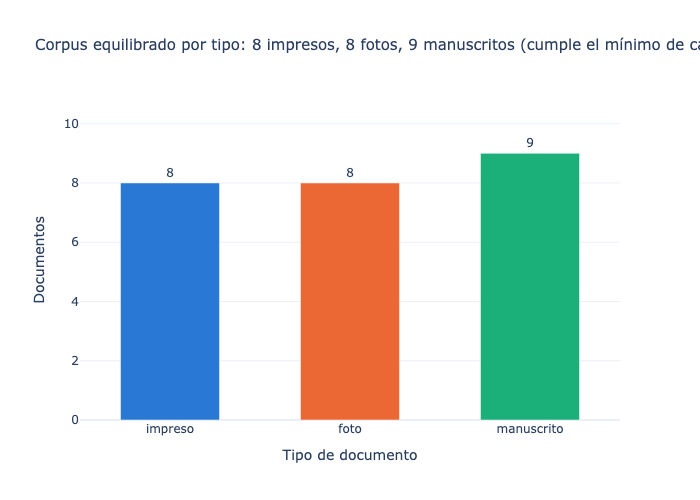

In [64]:
# 6.2 Gráfico 1: documentos por tipo
MINIMO = {"impreso": 8, "foto": 8, "manuscrito": 9}
por_tipo = docs_eda["tipo"].value_counts().reindex(ORDEN_TIPO).rename_axis("tipo").reset_index(name="documentos")
cumple = all(por_tipo.set_index("tipo")["documentos"] >= pd.Series(MINIMO))
detalle = ", ".join(f"{n} {t}s" for t, n in zip(por_tipo["tipo"], por_tipo["documentos"]))
titulo = (f"Corpus equilibrado por tipo: {detalle}" + (" (cumple el mínimo de cada tipo)" if cumple
          else " (NO cumple el mínimo de algún tipo)"))

fig = px.bar(por_tipo, x="tipo", y="documentos", color="tipo", color_discrete_map=COLOR_TIPO,
             text="documentos", title=titulo, labels={"tipo": "Tipo de documento", "documentos": "Documentos"})
fig.update_traces(textposition="outside", width=0.55, hovertemplate="%{x}: %{y} documentos<extra></extra>")
fig.update_layout(showlegend=False, yaxis_range=[0, por_tipo["documentos"].max() * 1.2], title_font_size=15)
fig.show()

Python(96687) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


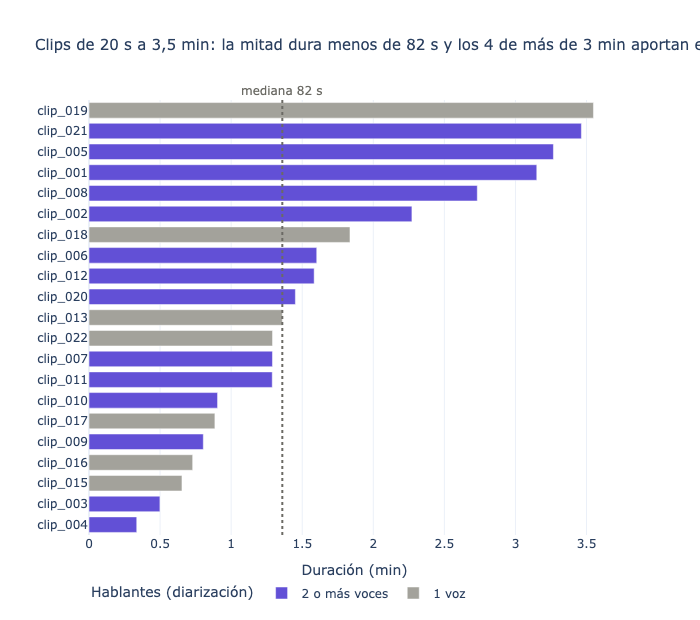

In [65]:
# 6.3 Gráfico 2: duración de cada clip (ordenados de más corto a más largo)
dur = clips_eda.sort_values("duracion_seg").assign(
    minutos=lambda d: d["duracion_seg"] / 60,
    voces=lambda d: np.where(d["n_hablantes"] > 1, "2 o más voces", "1 voz"))
total_min = dur["minutos"].sum()
mediana_s = dur["duracion_seg"].median()
largos = dur[dur["duracion_seg"] > 180]
max_min = f"{dur['minutos'].max():.1f}".replace(".", ",")  # coma decimal
titulo = (f"Clips de {dur['duracion_seg'].min():.0f} s a {max_min} min: la mitad dura menos de "
          f"{mediana_s:.0f} s y los {len(largos)} de más de 3 min aportan el {largos['minutos'].sum() / total_min:.0%} "
          f"de los {total_min:.0f} min")

fig = px.bar(dur, x="minutos", y="id", orientation="h", color="voces",
             color_discrete_map={"2 o más voces": COLOR_CLIP, "1 voz": COLOR_GRIS},
             category_orders={"voces": ["2 o más voces", "1 voz"], "id": dur["id"].tolist()[::-1]},  # el más largo arriba
             hover_data={"descripcion": True, "n_hablantes": True, "minutos": ":.1f", "voces": False},
             title=titulo, labels={"minutos": "Duración (min)", "id": "", "voces": "Hablantes (diarización)"})
fig.add_vline(x=mediana_s / 60, line_dash="dot", line_color="#6b6a64")
fig.add_annotation(x=mediana_s / 60, y=1, yref="paper", yanchor="bottom", showarrow=False,
                   text=f"mediana {mediana_s:.0f} s", font_color="#6b6a64")
fig.update_layout(height=620, bargap=0.25, title_font_size=15, legend=dict(orientation="h", y=-0.1))
fig.show()

Python(96713) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


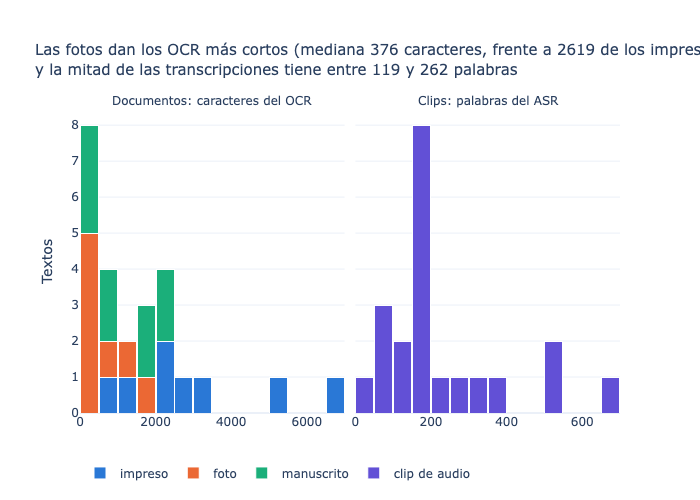

In [66]:
# 6.4 Gráfico 3: longitud de los textos extraídos (caracteres OCR por documento y palabras ASR por clip)
largo = pd.concat([
    docs_eda.assign(medida="Documentos: caracteres del OCR", valor=docs_eda["n_caracteres"], grupo=docs_eda["tipo"]),
    clips_eda.assign(medida="Clips: palabras del ASR", valor=clips_eda["n_palabras"], grupo="clip de audio"),
])[["id", "medida", "valor", "grupo"]]

med = docs_eda.groupby("tipo")["n_caracteres"].median()
q1, q3 = clips_eda["n_palabras"].quantile([0.25, 0.75])
titulo = (f"Las fotos dan los OCR más cortos (mediana {med['foto']:.0f} caracteres, frente a {med['impreso']:.0f} "
          f"de los impresos)<br>y la mitad de las transcripciones tiene entre {q1:.0f} y {q3:.0f} palabras")

fig = px.histogram(largo, x="valor", color="grupo", facet_col="medida", barmode="stack",
                   category_orders={"grupo": ORDEN_TIPO + ["clip de audio"],
                                    "medida": ["Documentos: caracteres del OCR", "Clips: palabras del ASR"]},
                   color_discrete_map={**COLOR_TIPO, "clip de audio": COLOR_CLIP},
                   title=titulo, labels={"grupo": "", "valor": ""})
# cada panel con sus propios intervalos: 500 caracteres en el OCR, 50 palabras en el ASR
fig.update_traces(xbins=dict(start=0, size=500), bingroup="ocr", selector=lambda t: t.name in ORDEN_TIPO)
fig.update_traces(xbins=dict(start=0, size=50), bingroup="asr", selector=dict(name="clip de audio"))
fig.update_xaxes(matches=None, showticklabels=True)
fig.update_yaxes(title_text="Textos", col=1)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_traces(marker_line_color="white", marker_line_width=1)
fig.update_layout(bargap=0.05, title_font_size=15, margin_t=110, legend=dict(orientation="h", y=-0.15))
fig.show()

## 7. Validación: casos extremos

Se muestran los 3 documentos con el OCR más largo y los 3 con el más corto, y lo mismo con los clips por duración, para comprobar que coinciden con los extremos de los histogramas. Los textos son los seudonimizados, y aquí solo se muestran los primeros 120 caracteres.

In [67]:
# 7.1 Documentos con el OCR más largo y más corto
def extremos(df, col, n=3):
    orden = df.sort_values(col, ascending=False)
    return pd.concat([orden.head(n).assign(extremo="más largo"), orden.tail(n).assign(extremo="más corto")])

vista_docs = extremos(docs_eda, "n_caracteres").assign(
    inicio_texto=lambda d: d["texto_seudonimizado"].str.replace(r"\s+", " ", regex=True).str[:120])
vista_docs[["extremo", "id", "tipo", "n_caracteres", "conf_media", "descripcion", "inicio_texto"]]

,extremo,id,tipo,n_caracteres,conf_media,descripcion,inicio_texto
1,más largo,doc_002,impreso,6722,0.979,Página de Normas Legales de El Peruano: modifi...,6 DISPOSICIONES COMPLEMENTARIAS FINALES Primer...
7,más largo,doc_008,impreso,5142,0.942,Página de El Peruano (10-04-1844) con el repor...,EL PERUANO PERIODIOOOFIOIAL. SE PUBLICA MIERCO...
5,más largo,doc_006,impreso,3335,0.978,Edición extraordinaria de Normas Legales de El...,El Peruano Fimado Digitalmente por. EMPRESA PE...
11,más corto,doc_014,foto,124,0.830,Foto de documentos manuscritos en una vitrina ...,TINTERO DE PORCELANA LEZLEMO DE LOBCETY E INST...
10,más corto,doc_011,foto,58,0.429,Foto de una lámina de la Nueva corónica en una...,iVLiO 248 1 RACVUACVI. CHAVAVAROVM uallauiza.p...
8,más corto,doc_009,foto,51,0.326,Foto de una lámina de la Nueva corónica en una...,a = = 11 H 120 − 7 2 To 0 LAPRIMERAHESREO


In [68]:
# 7.2 Clips más largos y más cortos
vista_clips = extremos(clips_eda, "duracion_seg").assign(
    inicio_texto=lambda d: d["texto_seudonimizado"].str.replace(r"\s+", " ", regex=True).str[:120])
vista_clips[["extremo", "id", "duracion_seg", "n_palabras", "n_hablantes", "descripcion", "inicio_texto"]]

,extremo,id,duracion_seg,n_palabras,n_hablantes,descripcion,inicio_texto
17,más largo,clip_019,212.93,674,1,Testimonio sobre salas de cine y memoria (proy...,[HABLANTE_1] Yo he ido a muchas salas de las q...
19,más largo,clip_021,207.84,535,3,Testimonio sobre salas de cine y memoria (proy...,"[HABLANTE_1] Ya no existe ese cine, el cine Sa..."
4,más largo,clip_005,196.03,510,3,"Entrevista callejera por Fiestas Patrias 2022,...","[HABLANTE_1] A ver, a ver, ¿cuál es la pregunt..."
13,más corto,clip_015,39.24,74,1,Entrevista a una organizadora de la fiesta pat...,"[HABLANTE_1] Buenos días, joven. Claro que sí,..."
2,más corto,clip_003,29.93,53,2,Mini entrevistas en el medio tiempo del partid...,[HABLANTE_1] normal esperando el resultado per...
3,más corto,clip_004,20.15,29,2,Impresiones de hinchas frente al partido Perú-...,[HABLANTE_1] ¿Cómo te sientes cuando hay parti...


In [69]:
# 7.3 ¿Coinciden con los histogramas?
rango_docs = docs_eda["n_caracteres"].agg(["min", "max"])
print(f"OCR: el histograma va de {rango_docs['min']} a {rango_docs['max']} caracteres; "
      f"los extremos de la tabla son {vista_docs['n_caracteres'].min()} y {vista_docs['n_caracteres'].max()}.")
print("Tipos de los 3 OCR más cortos:", ", ".join(vista_docs.query("extremo == 'más corto'")["tipo"]))
print("Tipos de los 3 OCR más largos:", ", ".join(vista_docs.query("extremo == 'más largo'")["tipo"]))

# en audio el histograma es de palabras: ¿los clips más largos son también los de más palabras?
rho = clips_eda["duracion_seg"].corr(clips_eda["n_palabras"], method="spearman")
rango_pal = clips_eda["n_palabras"].rank(ascending=False)
print(f"\nASR: correlación de Spearman entre duración y palabras = {rho:.2f}")
for e, ids in vista_clips.groupby("extremo")["id"]:
    puestos = rango_pal[clips_eda["id"].isin(ids)].astype(int).sort_values().tolist()
    print(f"Clips {e}s: puestos {puestos} de {len(clips_eda)} en número de palabras")

OCR: el histograma va de 51 a 6722 caracteres; los extremos de la tabla son 51 y 6722.
Tipos de los 3 OCR más cortos: foto, foto, foto
Tipos de los 3 OCR más largos: impreso, impreso, impreso

ASR: correlación de Spearman entre duración y palabras = 0.95
Clips más cortos: puestos [19, 20, 21] de 21 en número de palabras
Clips más largos: puestos [1, 2, 3] de 21 en número de palabras


### Lectura de la validación

**Documentos.** Los extremos de las tablas coinciden con los bordes del histograma: van de 51 a 6722 caracteres.

- **Los 3 OCR más largos son impresos:**
  - `doc_002`, una página de Normas Legales de *El Peruano* (6722 caracteres);
  - `doc_008`, *El Peruano* de 1844, a tres columnas (5142);
  - `doc_006`, un decreto de urgencia (3335).

  Son páginas densas de texto, y la confianza del OCR es alta (0,94–0,98).
- **Los 3 más cortos son fotos de vitrinas:** dos láminas de la Nueva corónica, `doc_009` (51) y `doc_011` (58), y los manuscritos de `doc_014` (124). Tienen poco texto legible y las confianzas más bajas del corpus (0,33–0,83).

  Son los mismos documentos marcados para revisión en el paso 2: se conservaron porque tienen algo de texto reconocible. Explican la barra naranja pegada a cero en el histograma.

**Clips.** La duración y el número de palabras van casi en el mismo orden (Spearman 0,95):

- **Los 3 más largos** (`clip_019`, `clip_021` y `clip_005`, de 3,3 a 3,5 min) son también los de más palabras. Ocupan los puestos 1 a 3 y forman la cola derecha del histograma de palabras (510–674).
- **Los 3 más cortos** (`clip_004`, `clip_003` y `clip_015`, de 20 a 39 s) son los de menos palabras (29–74).

No hay clips con mucha duración y poco texto, que es la señal de silencio o de una omisión grande del ASR.

## 8. Exportación

Se guardan los tres CSV publicables en `datos/`:

| Archivo | Columnas obligatorias | De dónde sale el texto |
|---|---|---|
| `documentos.csv` | id, archivo, tipo, fuente, texto_ocr, modelo_ocr, texto_referencia | OCR **seudonimizado** (paso 4) de los 25 documentos válidos |
| `transcripciones.csv` | id, archivo_audio, duracion_seg, idioma, texto_asr, modelo_asr, n_hablantes, texto_referencia | ASR **seudonimizado**, con las marcas `[HABLANTE_n]`, de los 21 clips válidos |
| `fuentes.csv` | id, modalidad, fuente_url, licencia, acceso | todos los archivos descargados, incluidos los descartados (columnas `descartado` y `motivo_descarte`) |

Detalles:
- `fuente` (en `documentos.csv`) es el enlace permanente al archivo en Wikimedia Commons.
- `texto_referencia` queda vacío por ahora y se completa en la Parte 2, con las transcripciones manuales de 10 documentos y 10 clips.
- En `fuentes.csv`, la columna `acceso` explica cómo recuperar cada archivo, porque los originales (`datos/raw/`) no se suben a Git.

In [70]:
# 8.1 datos/documentos.csv y datos/transcripciones.csv (solo texto seudonimizado)
documentos = (docs_eda.rename(columns={"fuente_url": "fuente", "texto_seudonimizado": "texto_ocr"})
              .assign(texto_referencia=pd.NA)
              [["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia"]]
              .sort_values("id").reset_index(drop=True))
transcripciones = (clips_eda.rename(columns={"archivo": "archivo_audio", "texto_seudonimizado": "texto_asr"})
                   .assign(texto_referencia=pd.NA)
                   [["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes",
                     "texto_referencia"]]
                   .sort_values("id").reset_index(drop=True))
documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)

In [71]:
# 8.2 datos/fuentes.csv con id, modalidad, fuente_url, licencia y acceso al inicio
fuentes = fuentes.rename(columns={"url": "fuente_url"})  # por si se carga una versión anterior
fuentes["modalidad"] = fuentes["corpus"].map({"documentos": "documento", "audio": "audio"})
fuentes["acceso"] = ("Abrir fuente_url (Wikimedia Commons) y usar «Descargar archivo original». "
                     + fuentes["procedimiento"] + ". Copia local en " + fuentes["archivo"]
                     + " (no versionada en Git; datos/raw/).")
primeras = ["id", "modalidad", "fuente_url", "licencia", "acceso"]
fuentes = fuentes[primeras + [c for c in fuentes.columns if c not in primeras]]
fuentes.to_csv(DATOS / "fuentes.csv", index=False)

for nombre, df in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(f"datos/{nombre}.csv: {df.shape}")

datos/documentos.csv: (25, 7)
datos/transcripciones.csv: (21, 8)
datos/fuentes.csv: (51, 23)


In [72]:
# 8.3 Primeras 5 filas de cada corpus
documentos.head()

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,https://commons.wikimedia.org/?curid=88144929,+\nDecreto Supremo\nEL PRESIDENTE DE LA·REPÚBL...,PaddleOCR 3.7.0 · PP-OCRv5_mobile_det + latin_...,<NA>
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,https://commons.wikimedia.org/?curid=88957144,6\nDISPOSICIONES COMPLEMENTARIAS FINALES\nPrim...,PaddleOCR 3.7.0 · PP-OCRv5_mobile_det + latin_...,<NA>
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,https://commons.wikimedia.org/?curid=88146070,Dirección General\nPERÚ\nMinisterio\nViceminis...,PaddleOCR 3.7.0 · PP-OCRv5_mobile_det + latin_...,<NA>
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,https://commons.wikimedia.org/?curid=89147685,PERÚ\nPresidencia\ndel Consejo de Ministros\nL...,PaddleOCR 3.7.0 · PP-OCRv5_mobile_det + latin_...,<NA>
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,https://commons.wikimedia.org/?curid=88144980,ANUNCIO DE DECRETO SUPREMO QUE DECLARA ESTADO ...,PaddleOCR 3.7.0 · PP-OCRv5_mobile_det + latin_...,<NA>


In [73]:
transcripciones.head()

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,clip_001,datos/raw/audio/clip_001.wav,189.01,es,[HABLANTE_1] Buenos días profesor y compañeros...,faster-whisper 1.2.1 · Whisper large-v3-turbo ...,3,<NA>
1,clip_002,datos/raw/audio/clip_002.wav,136.30,es,"[HABLANTE_1] Buenos días, aquí son las 10 y 28...",faster-whisper 1.2.1 · Whisper large-v3-turbo ...,2,<NA>
2,clip_003,datos/raw/audio/clip_003.wav,29.93,es,[HABLANTE_1] normal esperando el resultado per...,faster-whisper 1.2.1 · Whisper large-v3-turbo ...,2,<NA>
3,clip_004,datos/raw/audio/clip_004.wav,20.15,es,[HABLANTE_1] ¿Cómo te sientes cuando hay parti...,faster-whisper 1.2.1 · Whisper large-v3-turbo ...,2,<NA>
4,clip_005,datos/raw/audio/clip_005.wav,196.03,es,"[HABLANTE_1] A ver, a ver, ¿cuál es la pregunt...",faster-whisper 1.2.1 · Whisper large-v3-turbo ...,3,<NA>


In [74]:
fuentes.head()

,id,modalidad,fuente_url,licencia,acceso,corpus,tipo,archivo,fuente,autor,...,alto_px,hablantes_segun_fuente,duracion_seg,segundos_voz,proporcion_voz,tiene_voz,descartado,motivo_descarte,fecha_descarga,procedimiento
0,doc_001,documento,https://commons.wikimedia.org/?curid=88144929,Dominio público,Abrir fuente_url (Wikimedia Commons) y usar «D...,documentos,impreso,datos/raw/documentos/doc_001.jpg,Wikimedia Commons (Dominio público),Presidencia de la República del Perú,...,2714.0,NaN,NaN,NaN,NaN,NaN,False,NaN,2026-10-25,Página 1 del PDF renderizada por Commons a 192...
1,doc_002,documento,https://commons.wikimedia.org/?curid=88957144,Dominio público,Abrir fuente_url (Wikimedia Commons) y usar «D...,documentos,impreso,datos/raw/documentos/doc_002.jpg,Wikimedia Commons (Dominio público),Presidencia del Consejo de Ministros del Perú,...,3060.0,NaN,NaN,NaN,NaN,NaN,False,NaN,2026-10-25,Página 1 del PDF renderizada por Commons a 192...
2,doc_003,documento,https://commons.wikimedia.org/?curid=88146070,Dominio público,Abrir fuente_url (Wikimedia Commons) y usar «D...,documentos,impreso,datos/raw/documentos/doc_003.jpg,Wikimedia Commons (Dominio público),Ministerio de Salud del Perú,...,2716.0,NaN,NaN,NaN,NaN,NaN,False,NaN,2026-10-25,Página 1 del PDF renderizada por Commons a 192...
3,doc_004,documento,https://commons.wikimedia.org/?curid=89147685,Dominio público,Abrir fuente_url (Wikimedia Commons) y usar «D...,documentos,impreso,datos/raw/documentos/doc_004.jpg,Wikimedia Commons (Dominio público),Presidencia del Consejo de Ministros del Perú,...,2716.0,NaN,NaN,NaN,NaN,NaN,False,NaN,2026-10-25,Página 1 del PDF renderizada por Commons a 192...
4,doc_005,documento,https://commons.wikimedia.org/?curid=88144980,Dominio público,Abrir fuente_url (Wikimedia Commons) y usar «D...,documentos,impreso,datos/raw/documentos/doc_005.jpg,Wikimedia Commons (Dominio público),Presidencia de la República del Perú,...,2716.0,NaN,NaN,NaN,NaN,NaN,False,NaN,2026-10-25,Página 1 del PDF renderizada por Commons a 192...
